# Entrenamiento de modelos Multicanal (EEG, EOG, EMG)

**Maestría en Inteligencia Artificial MAIA**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Entrenamiento supervisado con `XGBClassifier`, `Random Forest`, `Arbol de Decisiones`y `LightGBM` usando `train_multicanal_emg.csv` y `test_multicanal_emg.csv` (generados en `09_preprocess_base_models_EMG.ipynb`). El dataset conserva un único esquema de columnas para soportar inferencia cuando alguno de los canales `EEG` está presente y `EOG horizontal` y/o `EMG submental` son opcionales (12 combinaciones).

## Librerias

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.data.segmentation import CLASS_NAMES, INT_TO_CLASS


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

/Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuración

El entrenamiento excluye identificadores y columnas de control que pueden generar fuga de información (`recording_id`, `subject_code`, `split`, `epoch_idx_in_recording`). Tampoco se usan las columnas de disponibilidad de canales (`has_*`, `channel_count`, `channel_combo`): las features de un canal ausente quedan en `NaN`, así que el modelo ya sabe qué canales llegaron. Las features son 40: 14 por cada EEG, 7 del EOG y 5 del EMG.

In [ ]:
RANDOM_STATE = 42
CV_SPLITS = 5
N_ITER_SEARCH = 10
SCORING = "f1_macro"

TARGET_COLUMN = "y"
ID_COLUMNS = ["recording_id", "subject_code"]
CONTROL_COLUMNS = [
    "split",
    "epoch_idx_in_recording",
    "channel_combo",
    "channel_count",
    "has_eeg_fpz_cz",
    "has_eeg_pz_oz",
    "has_eog_horizontal",
    "has_emg_submental",
]
CATEGORICAL_COLUMNS = []

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "processed" / "train_multicanal_emg.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "modelos"
MODEL_DIR.mkdir(exist_ok=True)

TRAIN_PATH = DATA_DIR / "train_multicanal_emg.csv"
TEST_PATH = DATA_DIR / "test_multicanal_emg.csv"

COMPARISON_PATH = MODEL_DIR / "model_comparison_multicanal_emg.csv"
COMPARISON_BY_COMBO_PATH = MODEL_DIR / "model_comparison_by_channel_combo_multicanal_emg.csv"


def get_artifact_paths(model_slug):
    """Rutas de artefactos de un modelo, p. ej. `best-xgboost-multicanal-emg.joblib`."""
    return {
        "joblib": MODEL_DIR / f"best-{model_slug}-multicanal-emg.joblib",
        "info": MODEL_DIR / f"model_info_{model_slug}_multicanal_emg.json",
        "metrics_by_combo": MODEL_DIR / f"metrics_by_channel_combo_{model_slug}_multicanal_emg.csv",
        "per_class_by_combo": MODEL_DIR / f"per_class_metrics_by_channel_combo_{model_slug}_multicanal_emg.csv",
        "feature_importance": MODEL_DIR / f"feature_importance_{model_slug}_multicanal_emg.csv",
    }

## Carga de datos

In [3]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

display(train_df.head())
display(train_df[TARGET_COLUMN].value_counts().sort_index().rename("train_count"))
display(test_df[TARGET_COLUMN].value_counts().sort_index().rename("test_count"))
display(train_df["channel_combo"].value_counts().rename("train_rows_by_combo"))
display(test_df["channel_combo"].value_counts().rename("test_rows_by_combo"))

Train shape: (1803264, 51)
Test shape:  (539820, 51)


,channel_combo,channel_count,split,epoch_idx_in_recording,has_eeg_fpz_cz,has_eeg_pz_oz,has_eog_horizontal,has_emg_submental,recording_id,subject_code,...,EMG_submental__p90,EMG_submental__slope,EMG_submental__std,EOG_horizontal__beta_power_abs,EOG_horizontal__delta_power_abs,EOG_horizontal__delta_power_rel,EOG_horizontal__hjorth_mobility,EOG_horizontal__kurtosis,EOG_horizontal__p2p_robust,EOG_horizontal__saccade_count
0,eeg_fpz_cz,1,train,0,True,False,False,False,SC4001E0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,eeg_fpz_cz,1,train,1,True,False,False,False,SC4001E0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,eeg_fpz_cz,1,train,2,True,False,False,False,SC4001E0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,eeg_fpz_cz,1,train,3,True,False,False,False,SC4001E0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,eeg_fpz_cz,1,train,4,True,False,False,False,SC4001E0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


y
N1     197340
N2     643116
N3     126948
REM    241080
W      594780
Name: train_count, dtype: int64

y
N1      60924
N2     186468
N3      29520
REM     68940
W      193968
Name: test_count, dtype: int64

channel_combo
eeg_fpz_cz                                              150272
eeg_pz_oz                                               150272
eeg_fpz_cz__eeg_pz_oz                                   150272
eeg_fpz_cz__eog_horizontal                              150272
eeg_pz_oz__eog_horizontal                               150272
eeg_fpz_cz__eeg_pz_oz__eog_horizontal                   150272
eeg_fpz_cz__emg_submental                               150272
eeg_pz_oz__emg_submental                                150272
eeg_fpz_cz__eeg_pz_oz__emg_submental                    150272
eeg_fpz_cz__eog_horizontal__emg_submental               150272
eeg_pz_oz__eog_horizontal__emg_submental                150272
eeg_fpz_cz__eeg_pz_oz__eog_horizontal__emg_submental    150272
Name: train_rows_by_combo, dtype: int64

channel_combo
eeg_fpz_cz                                              44985
eeg_pz_oz                                               44985
eeg_fpz_cz__eeg_pz_oz                                   44985
eeg_fpz_cz__eog_horizontal                              44985
eeg_pz_oz__eog_horizontal                               44985
eeg_fpz_cz__eeg_pz_oz__eog_horizontal                   44985
eeg_fpz_cz__emg_submental                               44985
eeg_pz_oz__emg_submental                                44985
eeg_fpz_cz__eeg_pz_oz__emg_submental                    44985
eeg_fpz_cz__eog_horizontal__emg_submental               44985
eeg_pz_oz__eog_horizontal__emg_submental                44985
eeg_fpz_cz__eeg_pz_oz__eog_horizontal__emg_submental    44985
Name: test_rows_by_combo, dtype: int64

## Preparación de matrices

In [4]:
missing_columns = set(train_df.columns) ^ set(test_df.columns)
if missing_columns:
    raise ValueError(f"Train y test no tienen las mismas columnas: {missing_columns}")

excluded_columns = [TARGET_COLUMN, *ID_COLUMNS, *CONTROL_COLUMNS]
base_feature_columns = [column for column in train_df.columns if column not in excluded_columns]

X_train_raw = train_df[base_feature_columns].copy()
X_test_raw = test_df[base_feature_columns].copy()

X_train = pd.get_dummies(X_train_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_test = pd.get_dummies(X_test_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

for df in (X_train, X_test):
    bool_columns = df.select_dtypes(include="bool").columns
    df[bool_columns] = df[bool_columns].astype(np.int8)

feature_columns = X_train.columns.tolist()

y_train_names = train_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(train_df[TARGET_COLUMN]).astype(str)
y_test_names = test_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(test_df[TARGET_COLUMN]).astype(str)

label_encoder = LabelEncoder()
label_encoder.fit(CLASS_NAMES)
y_train = label_encoder.transform(y_train_names)
y_test = label_encoder.transform(y_test_names)
class_labels = np.array(CLASS_NAMES)

groups = train_df["subject_code"].astype(str).to_numpy()
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

print(f"Número de features: {len(feature_columns)}")
print(f"Clases: {class_labels.tolist()}")
print(f"Número de pacientes/grupos en train: {pd.Series(groups).nunique()}")
print(f"Columnas excluidas: {excluded_columns}")
display(pd.Series(feature_columns, name="features"))

Número de features: 40
Clases: ['W', 'N1', 'N2', 'N3', 'REM']
Número de pacientes/grupos en train: 62
Columnas excluidas: ['y', 'recording_id', 'subject_code', 'split', 'epoch_idx_in_recording', 'channel_combo', 'channel_count', 'has_eeg_fpz_cz', 'has_eeg_pz_oz', 'has_eog_horizontal', 'has_emg_submental']


0         EEG_Fpz-Cz__alpha_power_abs
1         EEG_Fpz-Cz__alpha_power_rel
2          EEG_Fpz-Cz__beta_power_abs
3          EEG_Fpz-Cz__beta_power_rel
4       EEG_Fpz-Cz__delta_alpha_ratio
5         EEG_Fpz-Cz__delta_power_abs
6         EEG_Fpz-Cz__delta_power_rel
7                   EEG_Fpz-Cz__sef95
8         EEG_Fpz-Cz__sigma_power_abs
9         EEG_Fpz-Cz__sigma_power_rel
10       EEG_Fpz-Cz__spectral_entropy
11      EEG_Fpz-Cz__theta_alpha_ratio
12        EEG_Fpz-Cz__theta_power_abs
13        EEG_Fpz-Cz__theta_power_rel
14         EEG_Pz-Oz__alpha_power_abs
15         EEG_Pz-Oz__alpha_power_rel
16          EEG_Pz-Oz__beta_power_abs
17          EEG_Pz-Oz__beta_power_rel
18       EEG_Pz-Oz__delta_alpha_ratio
19         EEG_Pz-Oz__delta_power_abs
20         EEG_Pz-Oz__delta_power_rel
21                   EEG_Pz-Oz__sef95
22         EEG_Pz-Oz__sigma_power_abs
23         EEG_Pz-Oz__sigma_power_rel
24        EEG_Pz-Oz__spectral_entropy
25       EEG_Pz-Oz__theta_alpha_ratio
26         E

In [5]:
X_train.head()

,EEG_Fpz-Cz__alpha_power_abs,EEG_Fpz-Cz__alpha_power_rel,EEG_Fpz-Cz__beta_power_abs,EEG_Fpz-Cz__beta_power_rel,EEG_Fpz-Cz__delta_alpha_ratio,EEG_Fpz-Cz__delta_power_abs,EEG_Fpz-Cz__delta_power_rel,EEG_Fpz-Cz__sef95,EEG_Fpz-Cz__sigma_power_abs,EEG_Fpz-Cz__sigma_power_rel,...,EMG_submental__p90,EMG_submental__slope,EMG_submental__std,EOG_horizontal__beta_power_abs,EOG_horizontal__delta_power_abs,EOG_horizontal__delta_power_rel,EOG_horizontal__hjorth_mobility,EOG_horizontal__kurtosis,EOG_horizontal__p2p_robust,EOG_horizontal__saccade_count
0,4.132619,0.010247,8.005553,0.019849,84.448240,348.99240,0.865313,6.25,3.506238,0.008694,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4.140185,0.007408,8.547596,0.015294,118.638700,491.18616,0.878890,5.25,1.985889,0.003553,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.420617,0.005397,6.731600,0.008219,165.688390,732.44490,0.894271,4.75,2.095118,0.002558,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5.159684,0.008336,13.300922,0.021489,104.480900,539.08844,0.870950,6.00,3.834363,0.006195,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4.296539,0.008489,8.148181,0.016099,103.137566,443.13455,0.875535,5.75,2.656312,0.005248,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Búsqueda de hiperparámetros con validación cruzada

Los cuatro modelos (`XGBoost`, `LightGBM`, `Random Forest` y `Árbol de Decisión`) se entrenan con el mismo protocolo para que la comparación sea justa:

- `RandomizedSearchCV` con `N_ITER_SEARCH` combinaciones por modelo.
- CV estratificada por clase y agrupada por `subject_code` (`StratifiedGroupKFold`). Así, todas las épocas de un mismo paciente quedan completas en train o validation dentro de cada fold. Los folds son idénticos para todos los modelos.
- Pesos de muestra balanceados (`sample_weight`) para compensar el desbalance de clases.
- Selección del mejor modelo por `f1_macro` y evaluación final en `test_multicanal_emg.csv`.

Las funciones siguientes encapsulan la búsqueda, la evaluación y el guardado de artefactos, para aplicar exactamente el mismo flujo a cada modelo.

In [6]:
cv = StratifiedGroupKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

LABEL_IDS = label_encoder.transform(class_labels)
CV_SUMMARY_COLUMNS = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "std_train_score",
    "params",
]

results = {}


def run_search(model_name, estimator, param_distributions):
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions,
        n_iter=N_ITER_SEARCH,
        scoring=SCORING,
        cv=cv,
        verbose=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train, groups=groups, sample_weight=sample_weights)

    print(f"[{model_name}] Mejor {SCORING} CV: {search.best_score_}")
    print("Mejores hiperparámetros:")
    display(search.best_params_)
    return search


def show_cv_results(search, top_n=10):
    cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    display(cv_results[CV_SUMMARY_COLUMNS].head(top_n))
    return cv_results

In [7]:
def evaluate_predictions(y_true, y_hat, labels, prefix=None):
    return {
        "channel_combo": prefix,
        "support": len(y_true),
        "accuracy": accuracy_score(y_true, y_hat),
        "macro_f1": f1_score(y_true, y_hat, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_hat),
        "cohens_kappa": cohen_kappa_score(y_true, y_hat),
    }


def evaluate_global(model_name, search):
    y_pred = search.best_estimator_.predict(X_test)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=LABEL_IDS,
        zero_division=0,
    )

    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "cohens_kappa": cohen_kappa_score(y_test, y_pred),
        "best_cv_macro_f1": search.best_score_,
        "best_params": search.best_params_,
    }

    per_class_metrics = pd.DataFrame(
        {
            "class": class_labels,
            "precision_per_class": precision,
            "recall_per_class": recall,
            "f1_per_class": f1,
            "support": support,
        }
    )

    print(f"=== {model_name} - evaluación global en test ===")
    display(pd.Series(metrics, name="value"))
    display(per_class_metrics)
    print(classification_report(y_test, y_pred, labels=LABEL_IDS, target_names=[str(label) for label in class_labels], zero_division=0))
    return y_pred, metrics, per_class_metrics


def evaluate_by_combo(model_name, y_pred):
    combo_metric_rows = []
    combo_per_class_rows = []

    test_eval_df = test_df[["channel_combo", "recording_id", "subject_code", TARGET_COLUMN]].copy()
    test_eval_df["y_true"] = y_test
    test_eval_df["y_pred"] = y_pred

    combo_metric_rows.append(evaluate_predictions(y_test, y_pred, LABEL_IDS, prefix="overall"))

    for combo_name, combo_df in test_eval_df.groupby("channel_combo", sort=True):
        combo_y_true = combo_df["y_true"].to_numpy()
        combo_y_pred = combo_df["y_pred"].to_numpy()
        combo_metric_rows.append(evaluate_predictions(combo_y_true, combo_y_pred, LABEL_IDS, prefix=combo_name))

        p, r, f, s = precision_recall_fscore_support(
            combo_y_true,
            combo_y_pred,
            labels=LABEL_IDS,
            zero_division=0,
        )
        for class_name, precision_i, recall_i, f1_i, support_i in zip(class_labels, p, r, f, s):
            combo_per_class_rows.append(
                {
                    "channel_combo": combo_name,
                    "class": class_name,
                    "precision_per_class": precision_i,
                    "recall_per_class": recall_i,
                    "f1_per_class": f1_i,
                    "support": support_i,
                }
            )

    metrics_by_combo = pd.DataFrame(combo_metric_rows).sort_values("channel_combo")
    per_class_by_combo = pd.DataFrame(combo_per_class_rows).sort_values(["channel_combo", "class"])

    display(metrics_by_combo)
    display(per_class_by_combo)

    plt.figure(figsize=(10, 5))
    sns.barplot(data=metrics_by_combo[metrics_by_combo["channel_combo"] != "overall"], x="channel_combo", y="macro_f1", color="#4C78A8")
    plt.title(f"Macro F1 por combinación de canales - {model_name}")
    plt.xlabel("Combinación de canales")
    plt.ylabel("Macro F1")
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()
    return test_eval_df, metrics_by_combo, per_class_by_combo


def plot_confusion_matrices(model_name, test_eval_df):
    conf_matrix = confusion_matrix(test_eval_df["y_true"], test_eval_df["y_pred"], labels=LABEL_IDS)
    conf_matrix_df = pd.DataFrame(conf_matrix, index=class_labels, columns=class_labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Matriz de confusión global - {model_name} multicanal con EMG")
    plt.xlabel("Predicción")
    plt.ylabel("Clase real")
    plt.tight_layout()
    plt.show()
    display(conf_matrix_df)

    for combo_name, combo_df in test_eval_df.groupby("channel_combo", sort=True):
        combo_conf_matrix = confusion_matrix(
            combo_df["y_true"],
            combo_df["y_pred"],
            labels=LABEL_IDS,
        )
        combo_conf_matrix_df = pd.DataFrame(combo_conf_matrix, index=class_labels, columns=class_labels)
        plt.figure(figsize=(7, 5))
        sns.heatmap(combo_conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
        plt.title(f"Matriz de confusión - {model_name} - {combo_name}")
        plt.xlabel("Predicción")
        plt.ylabel("Clase real")
        plt.tight_layout()
        plt.show()
        display(combo_conf_matrix_df)


def plot_feature_importance(model_name, model, top_n=30):
    feature_importance = pd.DataFrame(
        {
            "feature": feature_columns,
            "importance": model.feature_importances_,
        }
    ).sort_values("importance", ascending=False)

    plt.figure(figsize=(10, 10))
    sns.barplot(data=feature_importance.head(top_n), x="importance", y="feature", color="#4C78A8")
    plt.title(f"Top {top_n} importancia de variables - {model_name} multicanal con EMG")
    plt.xlabel("Importancia")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    display(feature_importance)
    return feature_importance


def save_artifacts(model_name, model_slug, search, metrics, metrics_by_combo, per_class_by_combo, feature_importance):
    paths = get_artifact_paths(model_slug)
    best_model = search.best_estimator_

    joblib.dump(
        {
            "model": best_model,
            "label_encoder": label_encoder,
            "feature_columns": feature_columns,
            "excluded_columns": excluded_columns,
            "categorical_columns": CATEGORICAL_COLUMNS,
            "class_labels": class_labels.tolist(),
        },
        paths["joblib"],
    )

    feature_importance.to_csv(paths["feature_importance"], index=False)
    metrics_by_combo.to_csv(paths["metrics_by_combo"], index=False)
    per_class_by_combo.to_csv(paths["per_class_by_combo"], index=False)

    info = {
        "model": model_name,
        **metrics,
        "feature_columns": feature_columns,
        "excluded_columns": excluded_columns,
        "metrics_by_channel_combo": metrics_by_combo.to_dict(orient="records"),
    }

    with open(paths["info"], "w") as f:
        json.dump(info, f, indent=4, default=str)

    results[model_name] = {
        "slug": model_slug,
        "search": search,
        "metrics": metrics,
        "metrics_by_combo": metrics_by_combo,
    }

    return paths

## Modelo 1: XGBoost

### Búsqueda de hiperparámetros

In [8]:
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_labels),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    subsample=0.7,
    colsample_bytree=0.8,
)

xgb_param_distributions = {
    "n_estimators": [200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "gamma": [0, 0.1, 0.3, 0.5, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
    "reg_lambda": [0.5, 1.0, 2.0],
}

xgb_search = run_search("XGBoost", xgb_model, xgb_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END gamma=0.3, learning_rate=0.08, max_depth=5, min_child_weight=1, n_estimators=500, reg_alpha=0.5, reg_lambda=1.0; total time= 6.9min
[CV] END gamma=0.3, learning_rate=0.08, max_depth=5, min_child_weight=1, n_estimators=500, reg_alpha=0.5, reg_lambda=1.0; total time= 6.9min
[CV] END gamma=0.3, learning_rate=0.08, max_depth=5, min_child_weight=1, n_estimators=500, reg_alpha=0.5, reg_lambda=1.0; total time= 6.9min
[CV] END gamma=0.3, learning_rate=0.08, max_depth=5, min_child_weight=1, n_estimators=500, reg_alpha=0.5, reg_lambda=1.0; total time= 6.9min
[CV] END gamma=0.3, learning_rate=0.08, max_depth=5, min_child_weight=1, n_estimators=500, reg_alpha=0.5, reg_lambda=1.0; total time= 7.0min
[CV] END gamma=0, learning_rate=0.03, max_depth=5, min_child_weight=5, n_estimators=500, reg_alpha=0.1, reg_lambda=2.0; total time= 7.2min
[CV] END gamma=0, learning_rate=0.03, max_depth=5, min_child_weight=5, n_estimators=500, reg_al

{'reg_lambda': 1.0,
 'reg_alpha': 0.5,
 'n_estimators': 500,
 'min_child_weight': 1,
 'max_depth': 5,
 'learning_rate': 0.08,
 'gamma': 0.3}

In [9]:
xgb_cv_results = show_cv_results(xgb_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
0,1,0.705738,0.012728,0.797249,0.002138,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estim..."
4,2,0.704223,0.013232,0.790973,0.002402,"{'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estim..."
1,3,0.701112,0.012163,0.761151,0.002986,"{'reg_lambda': 2.0, 'reg_alpha': 0.1, 'n_estim..."
9,4,0.698021,0.011678,0.774440,0.003095,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estim..."
2,5,0.695157,0.015283,0.896836,0.001559,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'n_estimat..."
3,6,0.694095,0.014959,0.900081,0.001257,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'n_estimat..."
8,7,0.694056,0.011570,0.747757,0.003273,"{'reg_lambda': 1.0, 'reg_alpha': 0, 'n_estimat..."
6,8,0.693318,0.011415,0.758888,0.002910,"{'reg_lambda': 1.0, 'reg_alpha': 0.01, 'n_esti..."
5,9,0.690152,0.012113,0.727365,0.003125,"{'reg_lambda': 0.5, 'reg_alpha': 0, 'n_estimat..."
7,10,0.680213,0.009843,0.719945,0.003465,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estim..."


### Evaluación global en test y por combinación de canales

=== XGBoost - evaluación global en test ===


accuracy                                                      0.727394
macro_f1                                                      0.675106
balanced_accuracy                                             0.721068
cohens_kappa                                                  0.634825
best_cv_macro_f1                                              0.705738
best_params          {'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estim...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.885677,0.848454,0.866666,193968
1,N1,0.345475,0.504251,0.410029,60924
2,N2,0.904752,0.656987,0.761216,186468
3,N3,0.583112,0.891497,0.705058,29520
4,REM,0.574186,0.704149,0.632561,68940


              precision    recall  f1-score   support

           W       0.89      0.85      0.87    193968
          N1       0.35      0.50      0.41     60924
          N2       0.90      0.66      0.76    186468
          N3       0.58      0.89      0.71     29520
         REM       0.57      0.70      0.63     68940

    accuracy                           0.73    539820
   macro avg       0.66      0.72      0.68    539820
weighted avg       0.77      0.73      0.74    539820



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,44985,0.673536,0.615726,0.664152,0.563870
2,eeg_fpz_cz__eeg_pz_oz,44985,0.731110,0.674549,0.717864,0.639228
3,eeg_fpz_cz__eeg_pz_oz__emg_submental,44985,0.753162,0.706334,0.749541,0.668770
4,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,44985,0.760920,0.712997,0.756283,0.678619
5,eeg_fpz_cz__eeg_pz_oz__eog_horizontal__emg_sub...,44985,0.778837,0.733686,0.773904,0.701761
6,eeg_fpz_cz__emg_submental,44985,0.704213,0.657899,0.711546,0.605848
7,eeg_fpz_cz__eog_horizontal,44985,0.738402,0.687965,0.735945,0.648687
8,eeg_fpz_cz__eog_horizontal__emg_submental,44985,0.758319,0.711946,0.758177,0.674916
9,eeg_pz_oz,44985,0.671824,0.594437,0.641212,0.561073
10,eeg_pz_oz__emg_submental,44985,0.691408,0.639278,0.685661,0.590298


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.302835,0.389206,0.340631,5077
2,eeg_fpz_cz,N2,0.911817,0.632151,0.746656,15539
3,eeg_fpz_cz,N3,0.553396,0.914228,0.689454,2460
4,eeg_fpz_cz,REM,0.422280,0.589208,0.491970,5745
0,eeg_fpz_cz,W,0.824374,0.795966,0.809921,16164
6,eeg_fpz_cz__eeg_pz_oz,N1,0.342300,0.483750,0.400914,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.914617,0.665229,0.770240,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.614859,0.915041,0.735501,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.521890,0.653612,0.580371,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.900204,0.871690,0.885718,16164


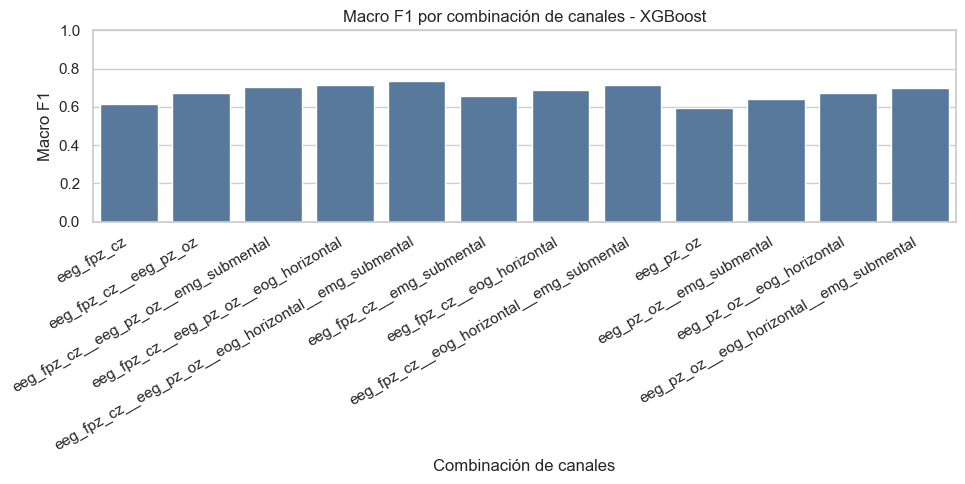

In [10]:
xgb_y_pred, xgb_metrics, xgb_per_class = evaluate_global("XGBoost", xgb_search)
xgb_test_eval_df, xgb_metrics_by_combo, xgb_per_class_by_combo = evaluate_by_combo("XGBoost", xgb_y_pred)

### Matriz de confusión global y por combinación

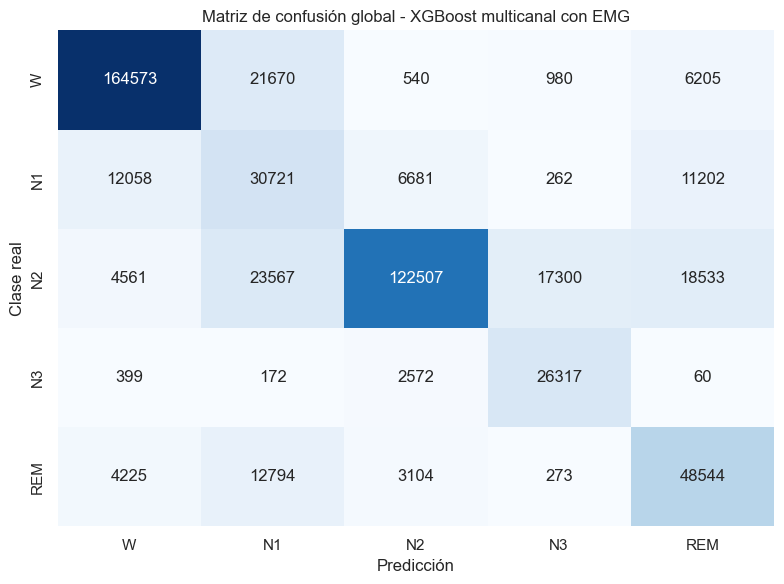

,W,N1,N2,N3,REM
W,164573,21670,540,980,6205
N1,12058,30721,6681,262,11202
N2,4561,23567,122507,17300,18533
N3,399,172,2572,26317,60
REM,4225,12794,3104,273,48544


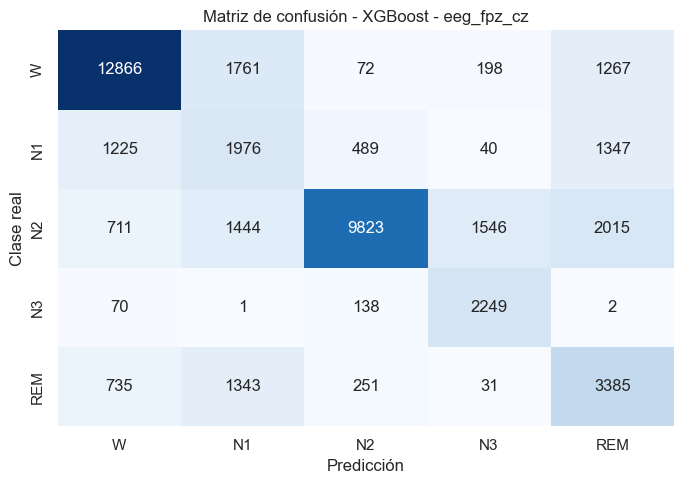

,W,N1,N2,N3,REM
W,12866,1761,72,198,1267
N1,1225,1976,489,40,1347
N2,711,1444,9823,1546,2015
N3,70,1,138,2249,2
REM,735,1343,251,31,3385


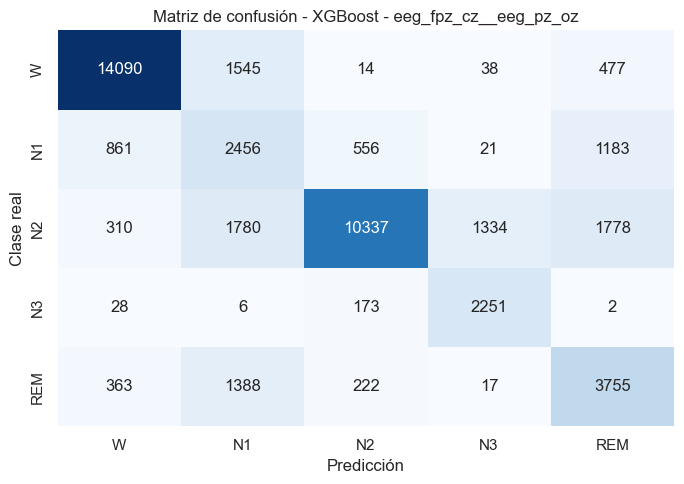

,W,N1,N2,N3,REM
W,14090,1545,14,38,477
N1,861,2456,556,21,1183
N2,310,1780,10337,1334,1778
N3,28,6,173,2251,2
REM,363,1388,222,17,3755


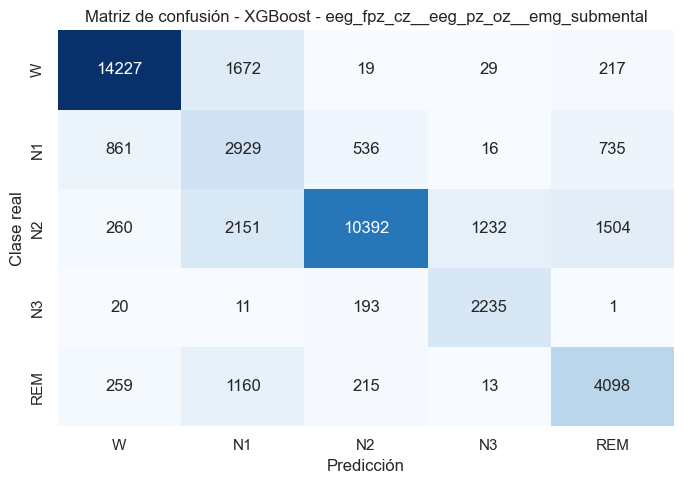

,W,N1,N2,N3,REM
W,14227,1672,19,29,217
N1,861,2929,536,16,735
N2,260,2151,10392,1232,1504
N3,20,11,193,2235,1
REM,259,1160,215,13,4098


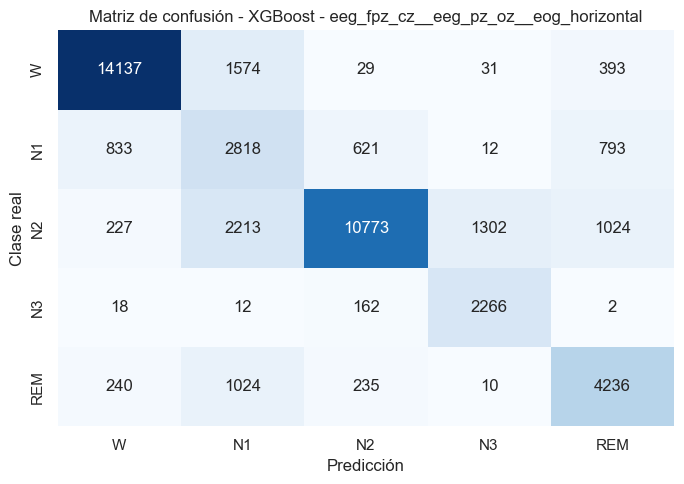

,W,N1,N2,N3,REM
W,14137,1574,29,31,393
N1,833,2818,621,12,793
N2,227,2213,10773,1302,1024
N3,18,12,162,2266,2
REM,240,1024,235,10,4236


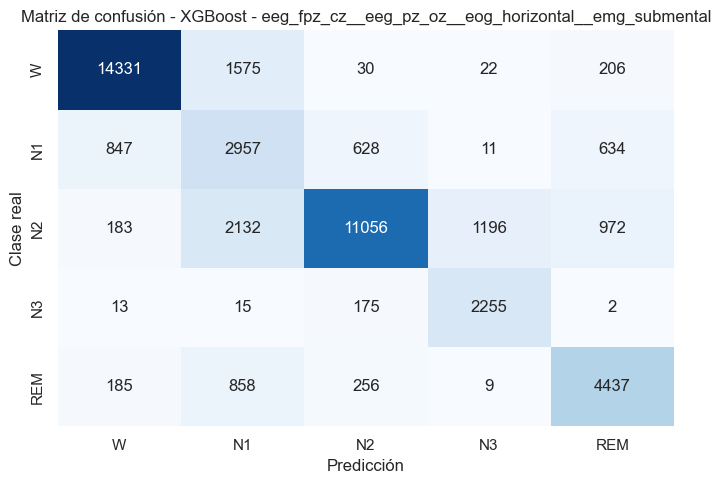

,W,N1,N2,N3,REM
W,14331,1575,30,22,206
N1,847,2957,628,11,634
N2,183,2132,11056,1196,972
N3,13,15,175,2255,2
REM,185,858,256,9,4437


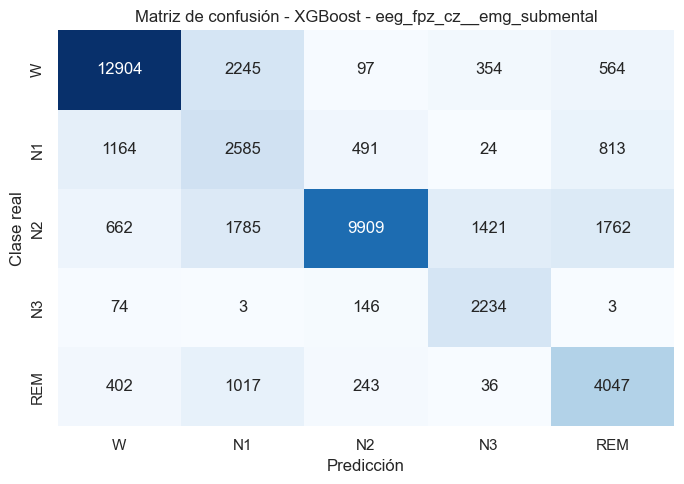

,W,N1,N2,N3,REM
W,12904,2245,97,354,564
N1,1164,2585,491,24,813
N2,662,1785,9909,1421,1762
N3,74,3,146,2234,3
REM,402,1017,243,36,4047


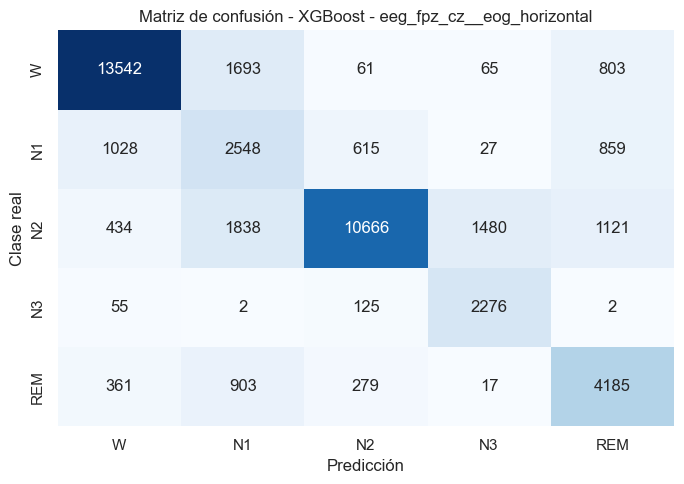

,W,N1,N2,N3,REM
W,13542,1693,61,65,803
N1,1028,2548,615,27,859
N2,434,1838,10666,1480,1121
N3,55,2,125,2276,2
REM,361,903,279,17,4185


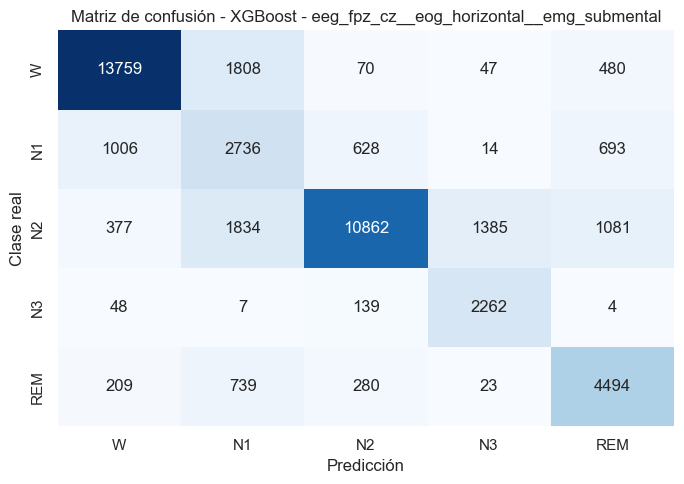

,W,N1,N2,N3,REM
W,13759,1808,70,47,480
N1,1006,2736,628,14,693
N2,377,1834,10862,1385,1081
N3,48,7,139,2262,4
REM,209,739,280,23,4494


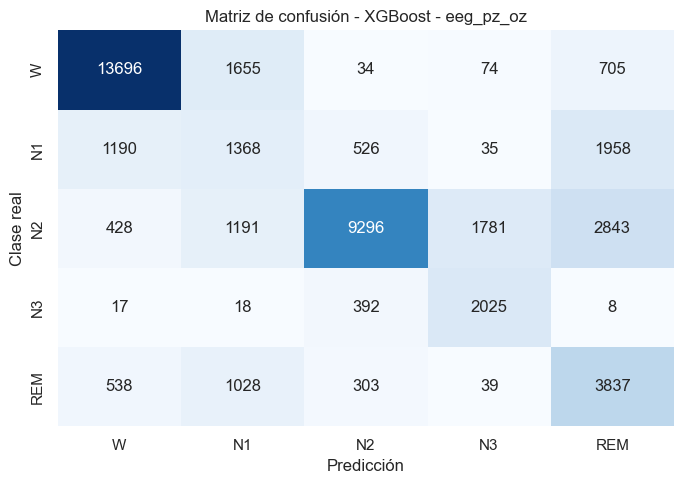

,W,N1,N2,N3,REM
W,13696,1655,34,74,705
N1,1190,1368,526,35,1958
N2,428,1191,9296,1781,2843
N3,17,18,392,2025,8
REM,538,1028,303,39,3837


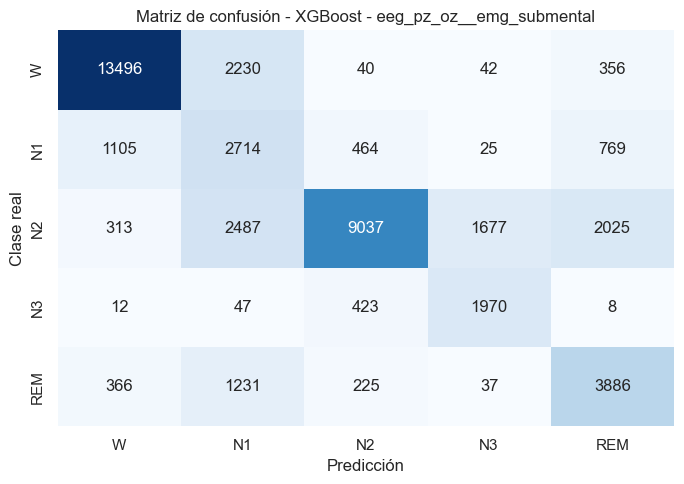

,W,N1,N2,N3,REM
W,13496,2230,40,42,356
N1,1105,2714,464,25,769
N2,313,2487,9037,1677,2025
N3,12,47,423,1970,8
REM,366,1231,225,37,3886


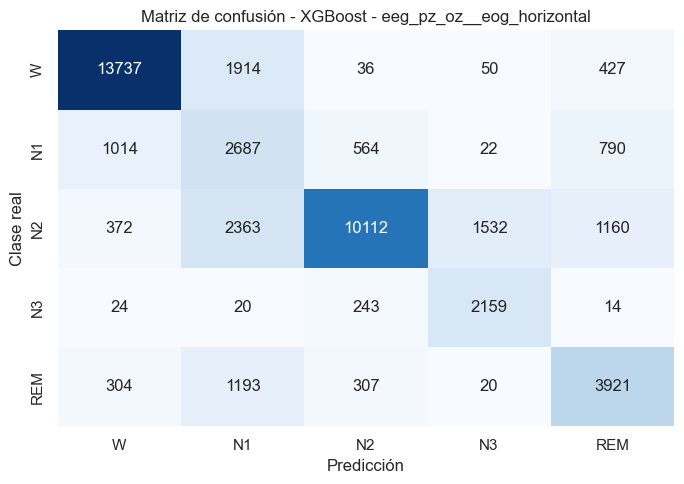

,W,N1,N2,N3,REM
W,13737,1914,36,50,427
N1,1014,2687,564,22,790
N2,372,2363,10112,1532,1160
N3,24,20,243,2159,14
REM,304,1193,307,20,3921


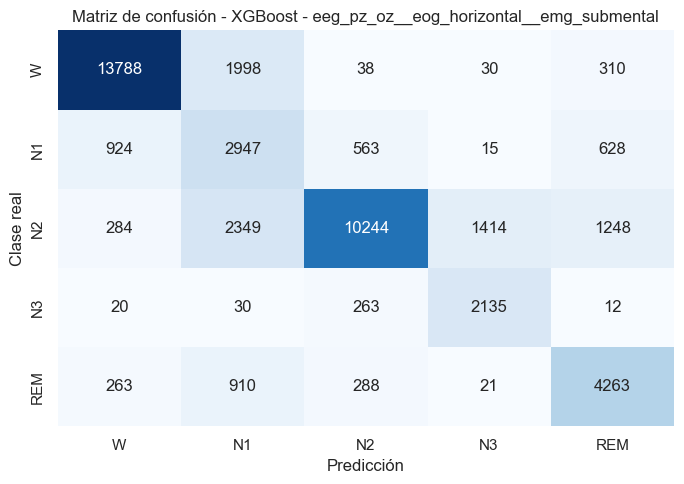

,W,N1,N2,N3,REM
W,13788,1998,38,30,310
N1,924,2947,563,15,628
N2,284,2349,10244,1414,1248
N3,20,30,263,2135,12
REM,263,910,288,21,4263


In [11]:
plot_confusion_matrices("XGBoost", xgb_test_eval_df)

### Importancia de variables y guardado de artefactos

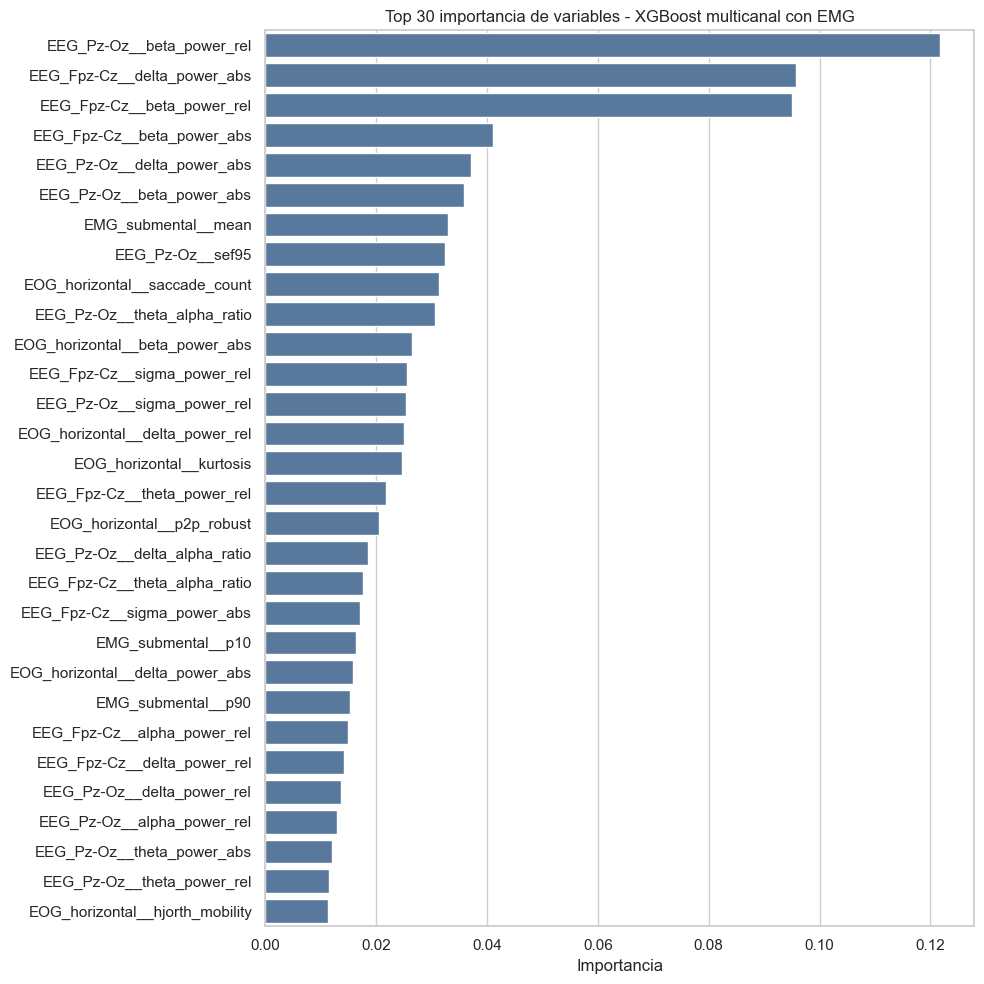

,feature,importance
17,EEG_Pz-Oz__beta_power_rel,0.121778
5,EEG_Fpz-Cz__delta_power_abs,0.095680
3,EEG_Fpz-Cz__beta_power_rel,0.095001
2,EEG_Fpz-Cz__beta_power_abs,0.040998
19,EEG_Pz-Oz__delta_power_abs,0.037030
16,EEG_Pz-Oz__beta_power_abs,0.035796
28,EMG_submental__mean,0.032897
21,EEG_Pz-Oz__sef95,0.032361
39,EOG_horizontal__saccade_count,0.031328
25,EEG_Pz-Oz__theta_alpha_ratio,0.030606


In [ ]:
xgb_feature_importance = plot_feature_importance("XGBoost", xgb_search.best_estimator_)

xgb_paths = save_artifacts(
    "XGBoost",
    "xgboost",
    xgb_search,
    xgb_metrics,
    xgb_metrics_by_combo,
    xgb_per_class_by_combo,
    xgb_feature_importance,
)

XGB_MODEL_PATH = MODEL_DIR / "best-xgboost-multicanal-emg-model.json"
xgb_search.best_estimator_.get_booster().save_model(XGB_MODEL_PATH)

## Modelo 2: LightGBM

### Búsqueda de hiperparámetros

In [13]:
lgbm_model = LGBMClassifier(
    objective="multiclass",
    num_class=len(class_labels),
    subsample_freq=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)

lgbm_param_distributions = {
    "n_estimators": [200, 300, 500, 700],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "num_leaves": [15, 31, 63, 127],
    "max_depth": [-1, 5, 8, 12],
    "min_child_samples": [20, 50, 100, 200],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
    "reg_lambda": [0, 0.5, 1.0, 2.0],
}

lgbm_search = run_search("LightGBM", lgbm_model, lgbm_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 6.0min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 6.0min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 6.0min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 6.1min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 6.0min
[CV] END learning_rate=0.03, max_depth=5, min_child_samples=50, n_estimators=200, num_leaves=15, reg_alpha=0.5, reg_lambda=1.0; total time= 2.5min
[CV] END learning_rate=0.03, max_depth=5, min_child_sampl

{'reg_lambda': 0,
 'reg_alpha': 0.01,
 'num_leaves': 31,
 'n_estimators': 200,
 'min_child_samples': 20,
 'max_depth': 12,
 'learning_rate': 0.05}

In [14]:
lgbm_cv_results = show_cv_results(lgbm_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
4,1,0.704330,0.012618,0.778364,0.002428,"{'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav..."
9,2,0.703659,0.014009,0.822114,0.002084,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'num_leave..."
8,3,0.703590,0.013829,0.809535,0.002158,"{'reg_lambda': 2.0, 'reg_alpha': 0.01, 'num_le..."
5,4,0.703543,0.013004,0.810524,0.002298,"{'reg_lambda': 0.5, 'reg_alpha': 0.1, 'num_lea..."
7,5,0.700526,0.011491,0.752602,0.002867,"{'reg_lambda': 1.0, 'reg_alpha': 0.1, 'num_lea..."
6,6,0.696832,0.014205,0.871259,0.001684,"{'reg_lambda': 1.0, 'reg_alpha': 0, 'num_leave..."
1,7,0.695291,0.010362,0.740395,0.002930,"{'reg_lambda': 0, 'reg_alpha': 0.5, 'num_leave..."
3,8,0.693852,0.015463,0.898920,0.001886,"{'reg_lambda': 0, 'reg_alpha': 0.5, 'num_leave..."
2,9,0.693560,0.010861,0.737005,0.003044,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'num_lea..."
0,10,0.685656,0.015881,0.932117,0.001523,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'num_leave..."


### Evaluación global en test y por combinación de canales

=== LightGBM - evaluación global en test ===


accuracy                                                      0.720372
macro_f1                                                      0.669113
balanced_accuracy                                             0.716874
cohens_kappa                                                  0.626231
best_cv_macro_f1                                               0.70433
best_params          {'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.882579,0.835499,0.858394,193968
1,N1,0.338320,0.506270,0.405597,60924
2,N2,0.904373,0.650712,0.756854,186468
3,N3,0.571193,0.890786,0.696057,29520
4,REM,0.569795,0.701102,0.628665,68940


              precision    recall  f1-score   support

           W       0.88      0.84      0.86    193968
          N1       0.34      0.51      0.41     60924
          N2       0.90      0.65      0.76    186468
          N3       0.57      0.89      0.70     29520
         REM       0.57      0.70      0.63     68940

    accuracy                           0.72    539820
   macro avg       0.65      0.72      0.67    539820
weighted avg       0.77      0.72      0.73    539820



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,44985,0.670868,0.611972,0.662337,0.560431
2,eeg_fpz_cz__eeg_pz_oz,44985,0.724353,0.666678,0.712529,0.630793
3,eeg_fpz_cz__eeg_pz_oz__emg_submental,44985,0.747360,0.700522,0.746439,0.661621
4,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,44985,0.753407,0.705587,0.750993,0.669153
5,eeg_fpz_cz__eeg_pz_oz__eog_horizontal__emg_sub...,44985,0.770546,0.726693,0.769453,0.691450
6,eeg_fpz_cz__emg_submental,44985,0.698055,0.652772,0.710299,0.598683
7,eeg_fpz_cz__eog_horizontal,44985,0.731155,0.681013,0.731898,0.639651
8,eeg_fpz_cz__eog_horizontal__emg_submental,44985,0.749805,0.704488,0.754787,0.664509
9,eeg_pz_oz,44985,0.666422,0.587752,0.634255,0.554063
10,eeg_pz_oz__emg_submental,44985,0.683228,0.635680,0.682375,0.581002


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.301860,0.380343,0.336587,5077
2,eeg_fpz_cz,N2,0.910338,0.631830,0.745935,15539
3,eeg_fpz_cz,N3,0.539049,0.917480,0.679103,2460
4,eeg_fpz_cz,REM,0.423359,0.591819,0.493612,5745
0,eeg_fpz_cz,W,0.819570,0.790213,0.804624,16164
6,eeg_fpz_cz__eeg_pz_oz,N1,0.334732,0.471538,0.391528,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.912204,0.656606,0.763583,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.596408,0.917886,0.723023,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.511765,0.651175,0.573114,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.899498,0.865442,0.882142,16164


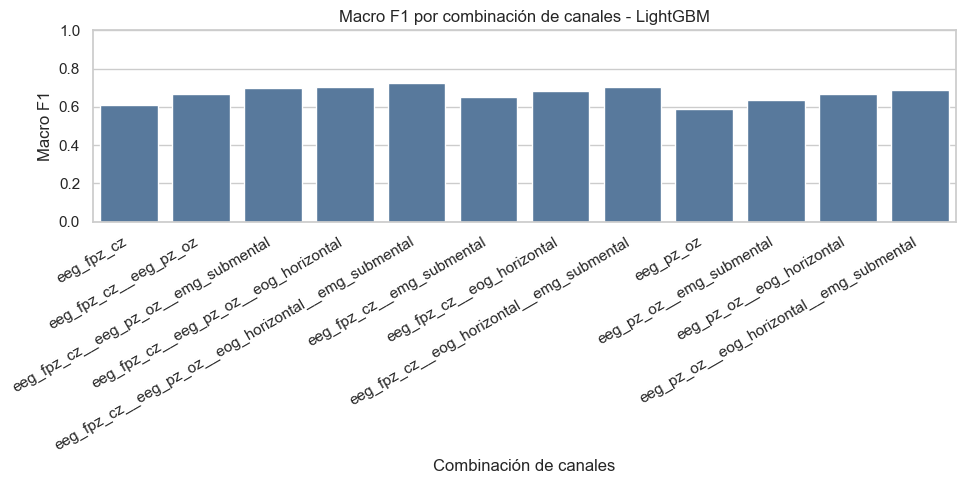

In [15]:
lgbm_y_pred, lgbm_metrics, lgbm_per_class = evaluate_global("LightGBM", lgbm_search)
lgbm_test_eval_df, lgbm_metrics_by_combo, lgbm_per_class_by_combo = evaluate_by_combo("LightGBM", lgbm_y_pred)

### Matriz de confusión global y por combinación

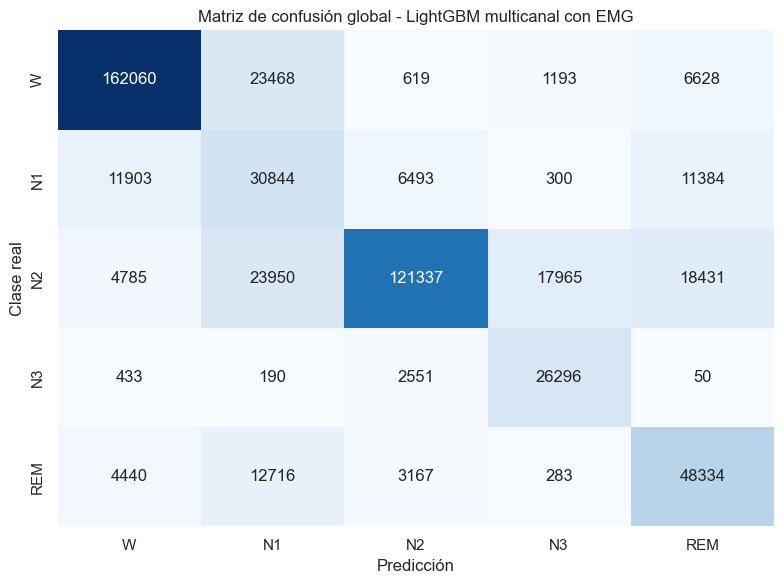

,W,N1,N2,N3,REM
W,162060,23468,619,1193,6628
N1,11903,30844,6493,300,11384
N2,4785,23950,121337,17965,18431
N3,433,190,2551,26296,50
REM,4440,12716,3167,283,48334


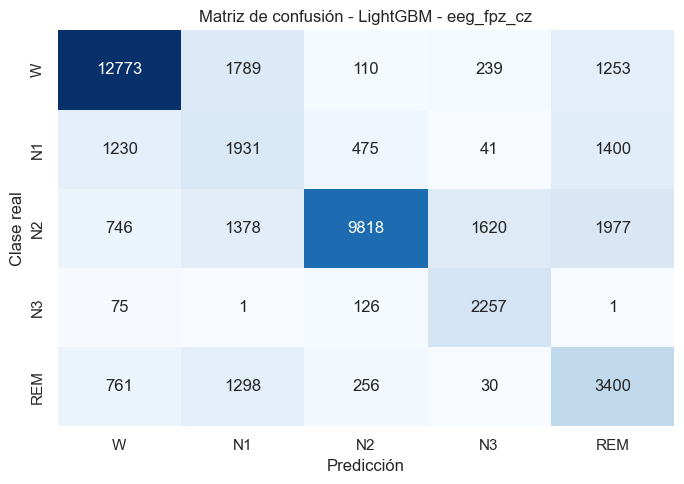

,W,N1,N2,N3,REM
W,12773,1789,110,239,1253
N1,1230,1931,475,41,1400
N2,746,1378,9818,1620,1977
N3,75,1,126,2257,1
REM,761,1298,256,30,3400


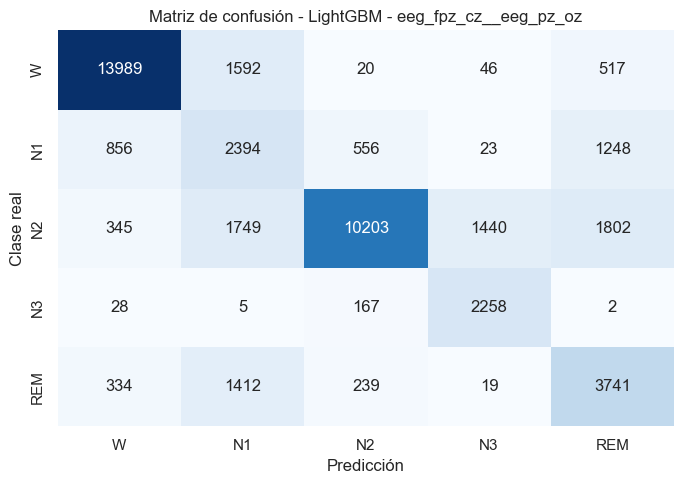

,W,N1,N2,N3,REM
W,13989,1592,20,46,517
N1,856,2394,556,23,1248
N2,345,1749,10203,1440,1802
N3,28,5,167,2258,2
REM,334,1412,239,19,3741


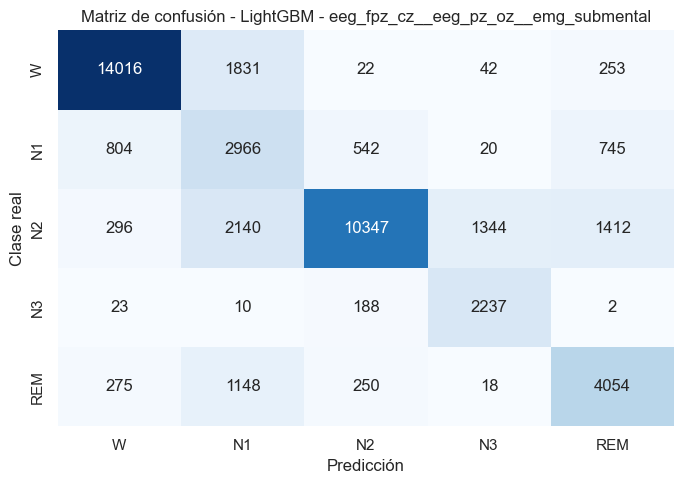

,W,N1,N2,N3,REM
W,14016,1831,22,42,253
N1,804,2966,542,20,745
N2,296,2140,10347,1344,1412
N3,23,10,188,2237,2
REM,275,1148,250,18,4054


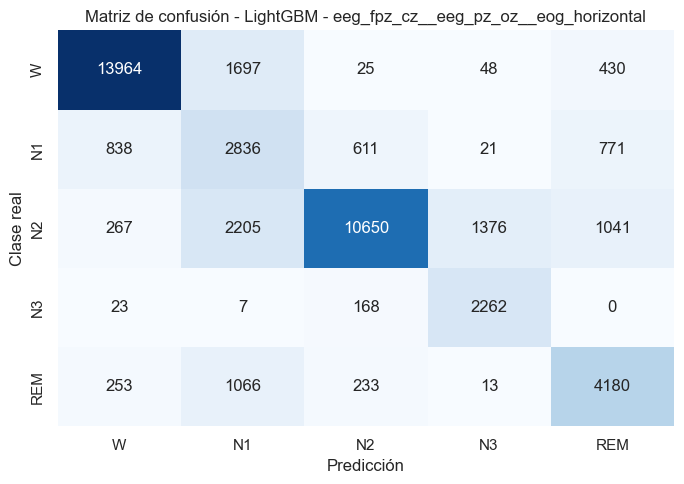

,W,N1,N2,N3,REM
W,13964,1697,25,48,430
N1,838,2836,611,21,771
N2,267,2205,10650,1376,1041
N3,23,7,168,2262,0
REM,253,1066,233,13,4180


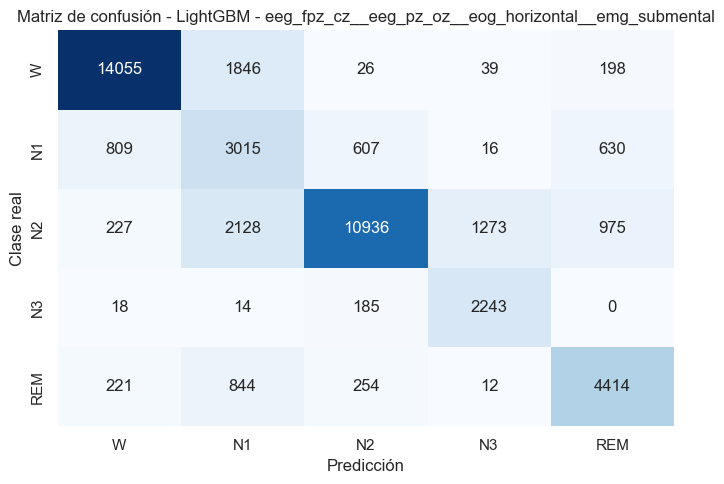

,W,N1,N2,N3,REM
W,14055,1846,26,39,198
N1,809,3015,607,16,630
N2,227,2128,10936,1273,975
N3,18,14,185,2243,0
REM,221,844,254,12,4414


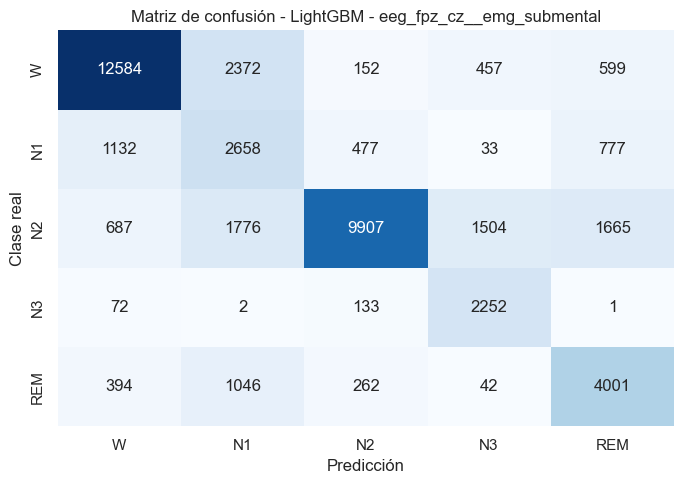

,W,N1,N2,N3,REM
W,12584,2372,152,457,599
N1,1132,2658,477,33,777
N2,687,1776,9907,1504,1665
N3,72,2,133,2252,1
REM,394,1046,262,42,4001


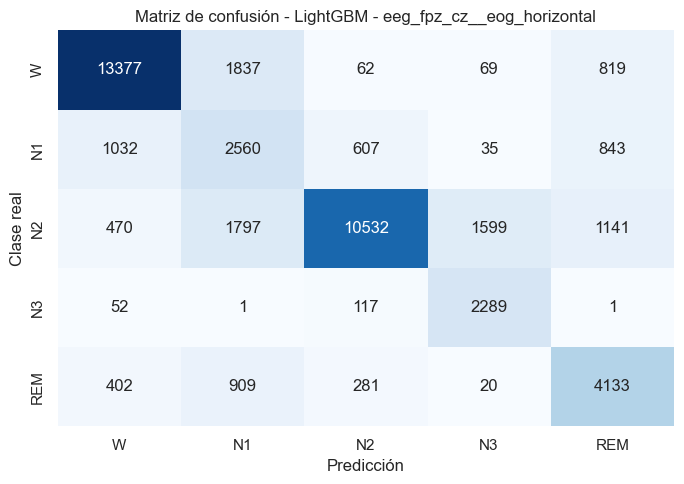

,W,N1,N2,N3,REM
W,13377,1837,62,69,819
N1,1032,2560,607,35,843
N2,470,1797,10532,1599,1141
N3,52,1,117,2289,1
REM,402,909,281,20,4133


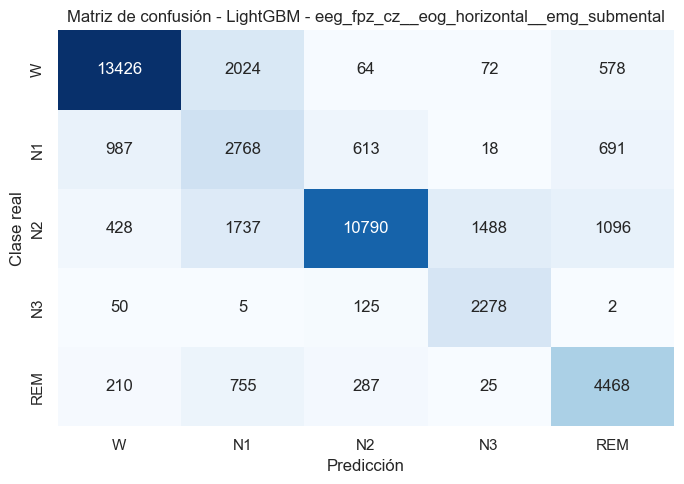

,W,N1,N2,N3,REM
W,13426,2024,64,72,578
N1,987,2768,613,18,691
N2,428,1737,10790,1488,1096
N3,50,5,125,2278,2
REM,210,755,287,25,4468


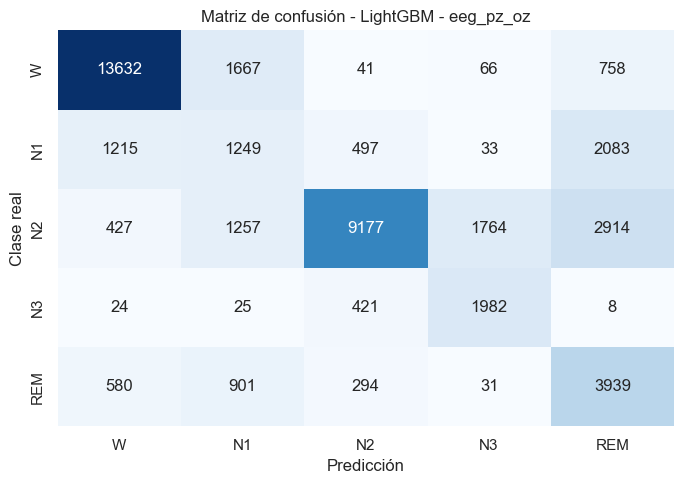

,W,N1,N2,N3,REM
W,13632,1667,41,66,758
N1,1215,1249,497,33,2083
N2,427,1257,9177,1764,2914
N3,24,25,421,1982,8
REM,580,901,294,31,3939


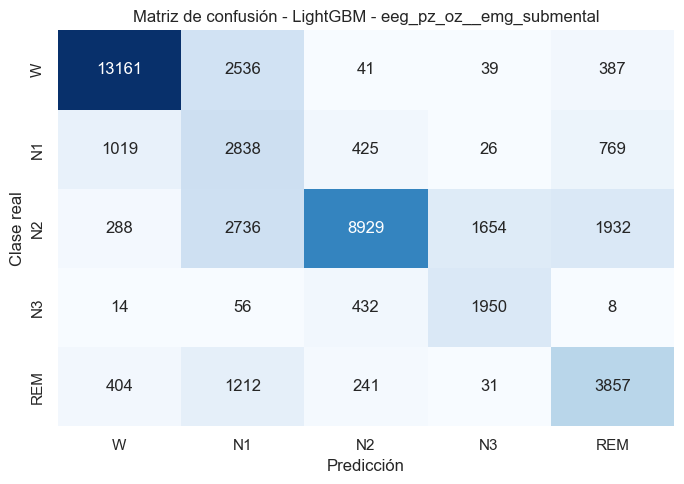

,W,N1,N2,N3,REM
W,13161,2536,41,39,387
N1,1019,2838,425,26,769
N2,288,2736,8929,1654,1932
N3,14,56,432,1950,8
REM,404,1212,241,31,3857


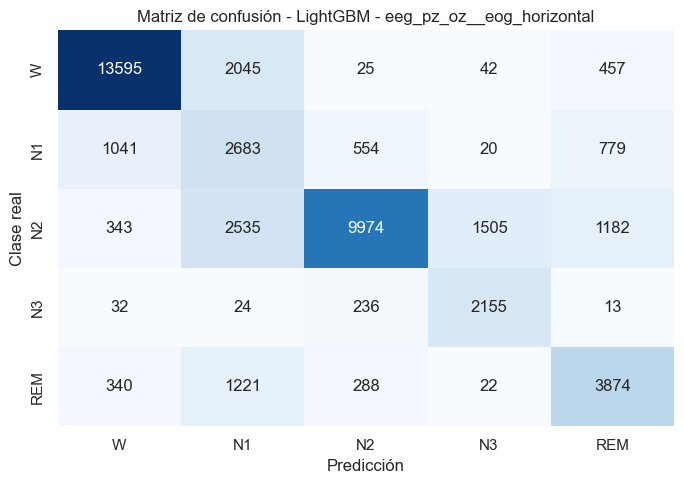

,W,N1,N2,N3,REM
W,13595,2045,25,42,457
N1,1041,2683,554,20,779
N2,343,2535,9974,1505,1182
N3,32,24,236,2155,13
REM,340,1221,288,22,3874


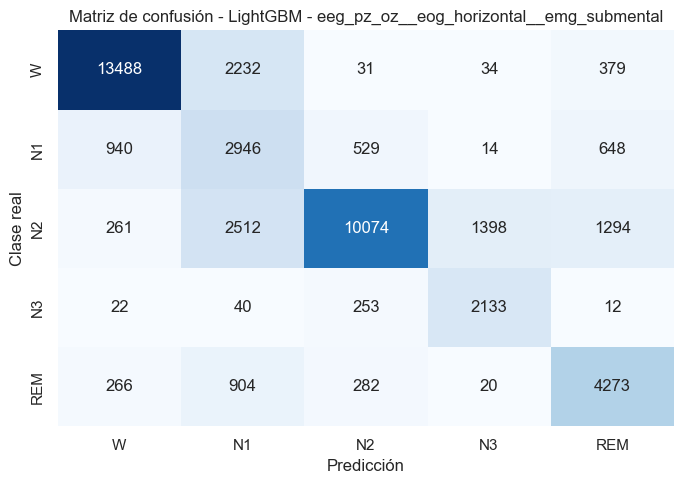

,W,N1,N2,N3,REM
W,13488,2232,31,34,379
N1,940,2946,529,14,648
N2,261,2512,10074,1398,1294
N3,22,40,253,2133,12
REM,266,904,282,20,4273


In [16]:
plot_confusion_matrices("LightGBM", lgbm_test_eval_df)

### Importancia de variables y guardado de artefactos

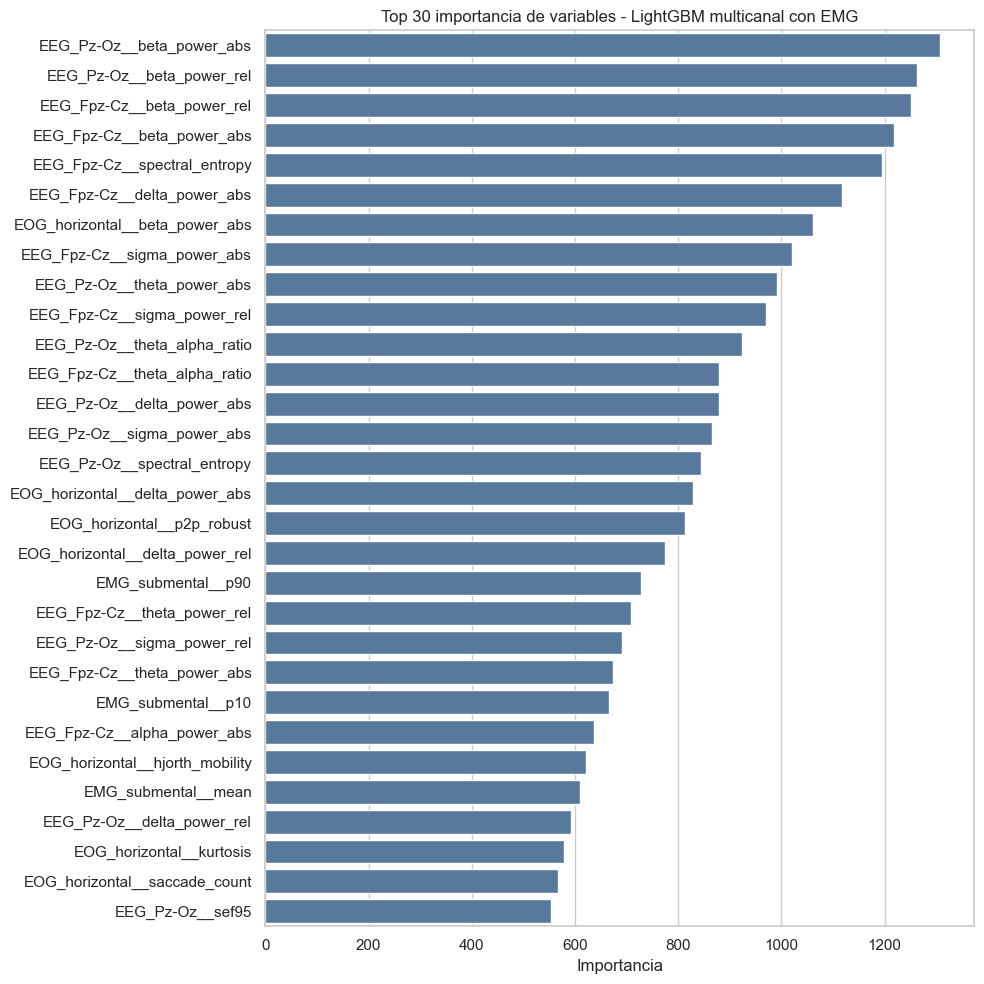

,feature,importance
16,EEG_Pz-Oz__beta_power_abs,1308
17,EEG_Pz-Oz__beta_power_rel,1263
3,EEG_Fpz-Cz__beta_power_rel,1252
2,EEG_Fpz-Cz__beta_power_abs,1218
10,EEG_Fpz-Cz__spectral_entropy,1196
5,EEG_Fpz-Cz__delta_power_abs,1117
33,EOG_horizontal__beta_power_abs,1061
8,EEG_Fpz-Cz__sigma_power_abs,1021
26,EEG_Pz-Oz__theta_power_abs,991
9,EEG_Fpz-Cz__sigma_power_rel,970


In [17]:
lgbm_feature_importance = plot_feature_importance("LightGBM", lgbm_search.best_estimator_)

lgbm_paths = save_artifacts(
    "LightGBM",
    "lightgbm",
    lgbm_search,
    lgbm_metrics,
    lgbm_metrics_by_combo,
    lgbm_per_class_by_combo,
    lgbm_feature_importance,
)

## Modelo 3: Random Forest

### Búsqueda de hiperparámetros

In [ ]:
rf_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_param_distributions = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15, 20, 25],
    "min_samples_split": [10, 50, 100],
    "min_samples_leaf": [5, 20, 50],
    "max_features": ["sqrt", "log2"],
    "max_samples": [0.1, 0.2, 0.3],
}

rf_search = run_search("Random Forest", rf_model, rf_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time=17.2min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time=17.3min
[CV] END max_depth=10, max_features=log2, max_samples=0.2, min_samples_leaf=5, min_samples_split=50, n_estimators=200; total time=17.4min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time=17.4min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time=17.4min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time=17.5min
[CV] END max_depth=10, max_features=log2, max_samples=0.2, min_samples_leaf=5, min_samples_split=50, 

{'n_estimators': 100,
 'min_samples_split': 100,
 'min_samples_leaf': 20,
 'max_samples': 0.3,
 'max_features': 'log2',
 'max_depth': 25}

In [19]:
rf_cv_results = show_cv_results(rf_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
0,1,0.695783,0.011061,0.797968,0.002101,"{'n_estimators': 100, 'min_samples_split': 100..."
5,2,0.694604,0.010679,0.766087,0.002388,"{'n_estimators': 200, 'min_samples_split': 100..."
6,3,0.693662,0.013199,0.882106,0.001073,"{'n_estimators': 100, 'min_samples_split': 10,..."
4,4,0.692172,0.010381,0.752452,0.002537,"{'n_estimators': 100, 'min_samples_split': 50,..."
2,5,0.691989,0.011358,0.779716,0.003121,"{'n_estimators': 100, 'min_samples_split': 10,..."
7,6,0.691985,0.010682,0.763112,0.002357,"{'n_estimators': 100, 'min_samples_split': 100..."
9,7,0.691623,0.010151,0.766789,0.002700,"{'n_estimators': 100, 'min_samples_split': 100..."
8,8,0.690567,0.010235,0.750309,0.002730,"{'n_estimators': 200, 'min_samples_split': 50,..."
1,9,0.673673,0.009607,0.716941,0.004510,"{'n_estimators': 200, 'min_samples_split': 50,..."
3,10,0.673232,0.010784,0.713295,0.004115,"{'n_estimators': 100, 'min_samples_split': 10,..."


### Evaluación global en test y por combinación de canales

=== Random Forest - evaluación global en test ===


accuracy                                                      0.714186
macro_f1                                                      0.663476
balanced_accuracy                                             0.707823
cohens_kappa                                                  0.617456
best_cv_macro_f1                                              0.695783
best_params          {'n_estimators': 100, 'min_samples_split': 100...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.869520,0.836612,0.852749,193968
1,N1,0.329140,0.500295,0.397059,60924
2,N2,0.900754,0.642925,0.750308,186468
3,N3,0.579132,0.877879,0.697878,29520
4,REM,0.567713,0.681404,0.619385,68940


              precision    recall  f1-score   support

           W       0.87      0.84      0.85    193968
          N1       0.33      0.50      0.40     60924
          N2       0.90      0.64      0.75    186468
          N3       0.58      0.88      0.70     29520
         REM       0.57      0.68      0.62     68940

    accuracy                           0.71    539820
   macro avg       0.65      0.71      0.66    539820
weighted avg       0.76      0.71      0.73    539820



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,44985,0.659175,0.603918,0.656184,0.546736
2,eeg_fpz_cz__eeg_pz_oz,44985,0.726731,0.668693,0.710378,0.632081
3,eeg_fpz_cz__eeg_pz_oz__emg_submental,44985,0.737135,0.690448,0.734379,0.647229
4,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,44985,0.751006,0.703492,0.742102,0.664507
5,eeg_fpz_cz__eeg_pz_oz__eog_horizontal__emg_sub...,44985,0.758186,0.714904,0.755338,0.674455
6,eeg_fpz_cz__emg_submental,44985,0.677204,0.632938,0.690911,0.572161
7,eeg_fpz_cz__eog_horizontal,44985,0.725397,0.678711,0.724504,0.631854
8,eeg_fpz_cz__eog_horizontal__emg_submental,44985,0.734845,0.691318,0.738004,0.644542
9,eeg_pz_oz,44985,0.669290,0.596212,0.639272,0.558254
10,eeg_pz_oz__emg_submental,44985,0.690230,0.638606,0.679091,0.587633


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.293739,0.413039,0.343320,5077
2,eeg_fpz_cz,N2,0.903100,0.626166,0.739558,15539
3,eeg_fpz_cz,N3,0.515502,0.905691,0.657033,2460
4,eeg_fpz_cz,REM,0.430543,0.575631,0.492626,5745
0,eeg_fpz_cz,W,0.815648,0.760393,0.787052,16164
6,eeg_fpz_cz__eeg_pz_oz,N1,0.343158,0.442584,0.386581,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.904887,0.667353,0.768177,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.618472,0.914634,0.737947,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.512529,0.658660,0.576478,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.879982,0.868659,0.874284,16164


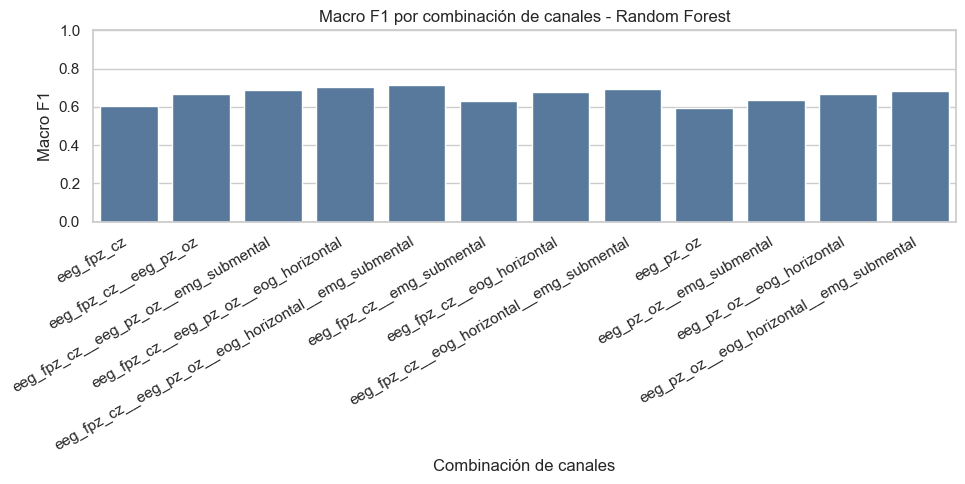

In [20]:
rf_y_pred, rf_metrics, rf_per_class = evaluate_global("Random Forest", rf_search)
rf_test_eval_df, rf_metrics_by_combo, rf_per_class_by_combo = evaluate_by_combo("Random Forest", rf_y_pred)

### Matriz de confusión global y por combinación

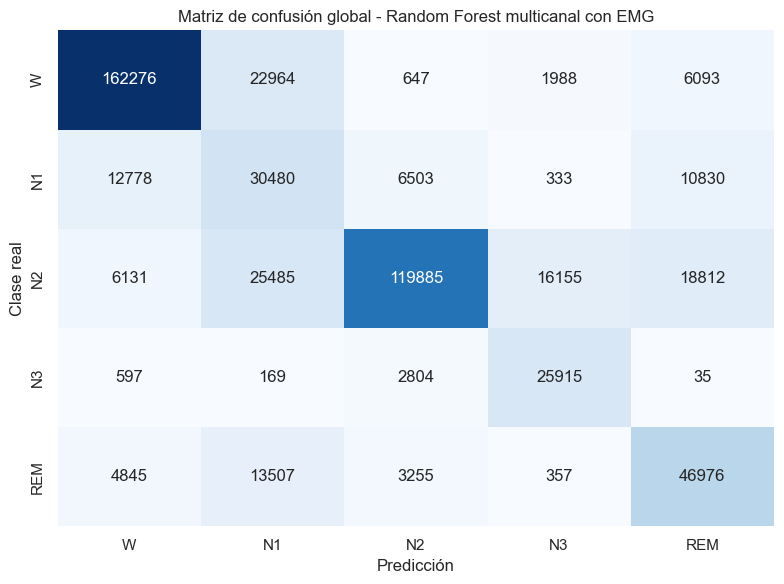

,W,N1,N2,N3,REM
W,162276,22964,647,1988,6093
N1,12778,30480,6503,333,10830
N2,6131,25485,119885,16155,18812
N3,597,169,2804,25915,35
REM,4845,13507,3255,357,46976


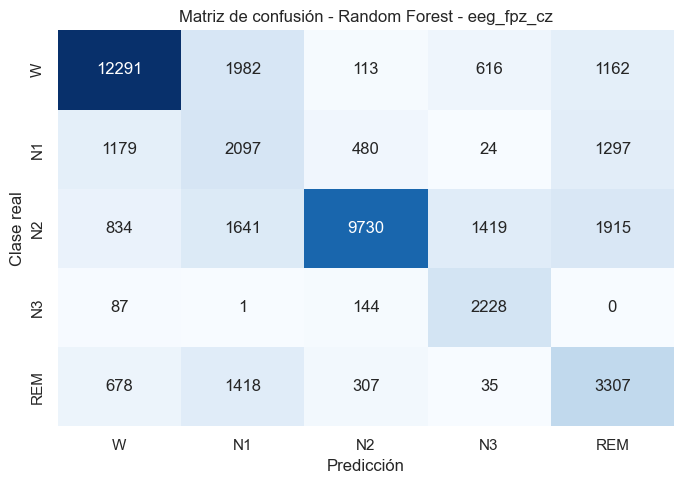

,W,N1,N2,N3,REM
W,12291,1982,113,616,1162
N1,1179,2097,480,24,1297
N2,834,1641,9730,1419,1915
N3,87,1,144,2228,0
REM,678,1418,307,35,3307


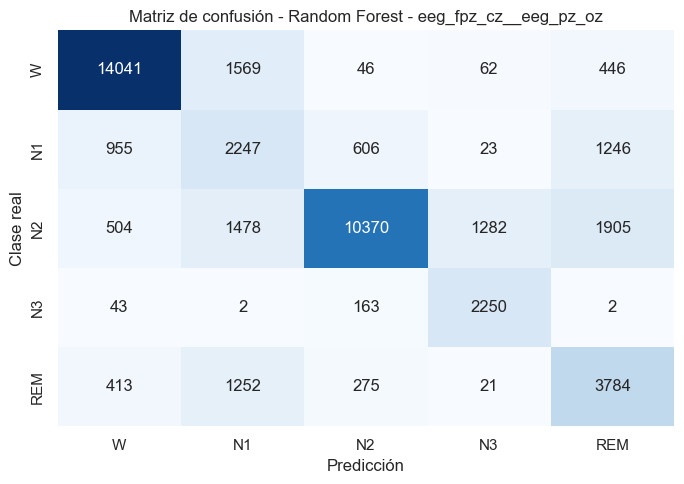

,W,N1,N2,N3,REM
W,14041,1569,46,62,446
N1,955,2247,606,23,1246
N2,504,1478,10370,1282,1905
N3,43,2,163,2250,2
REM,413,1252,275,21,3784


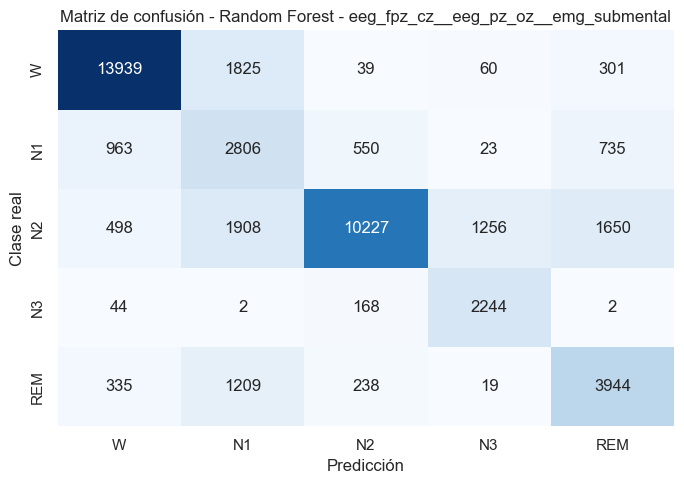

,W,N1,N2,N3,REM
W,13939,1825,39,60,301
N1,963,2806,550,23,735
N2,498,1908,10227,1256,1650
N3,44,2,168,2244,2
REM,335,1209,238,19,3944


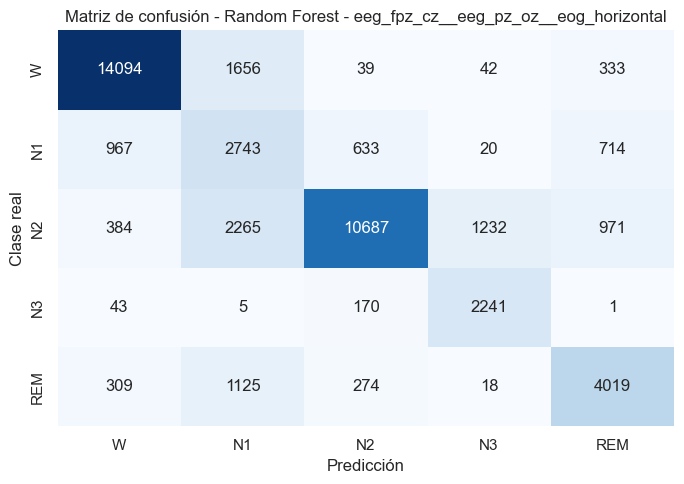

,W,N1,N2,N3,REM
W,14094,1656,39,42,333
N1,967,2743,633,20,714
N2,384,2265,10687,1232,971
N3,43,5,170,2241,1
REM,309,1125,274,18,4019


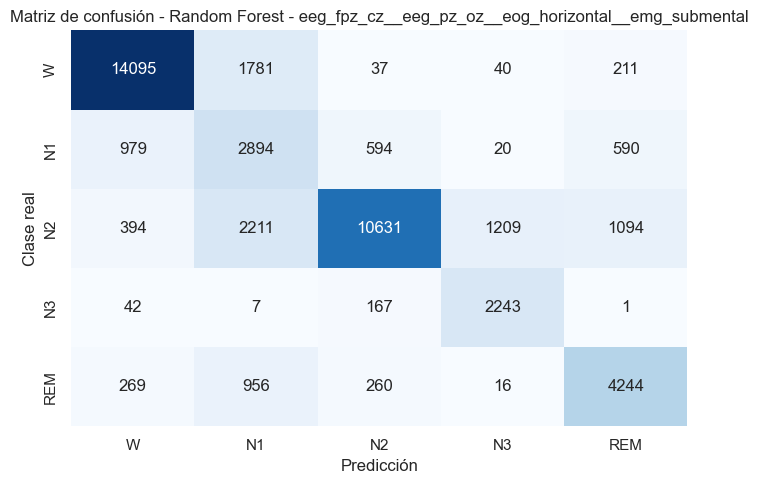

,W,N1,N2,N3,REM
W,14095,1781,37,40,211
N1,979,2894,594,20,590
N2,394,2211,10631,1209,1094
N3,42,7,167,2243,1
REM,269,956,260,16,4244


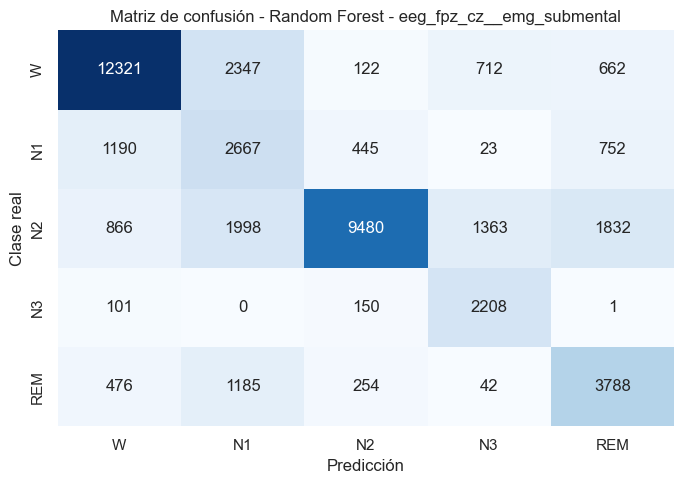

,W,N1,N2,N3,REM
W,12321,2347,122,712,662
N1,1190,2667,445,23,752
N2,866,1998,9480,1363,1832
N3,101,0,150,2208,1
REM,476,1185,254,42,3788


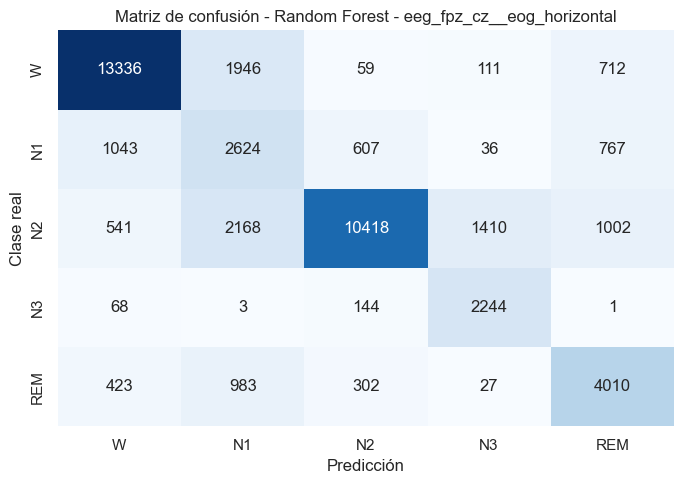

,W,N1,N2,N3,REM
W,13336,1946,59,111,712
N1,1043,2624,607,36,767
N2,541,2168,10418,1410,1002
N3,68,3,144,2244,1
REM,423,983,302,27,4010


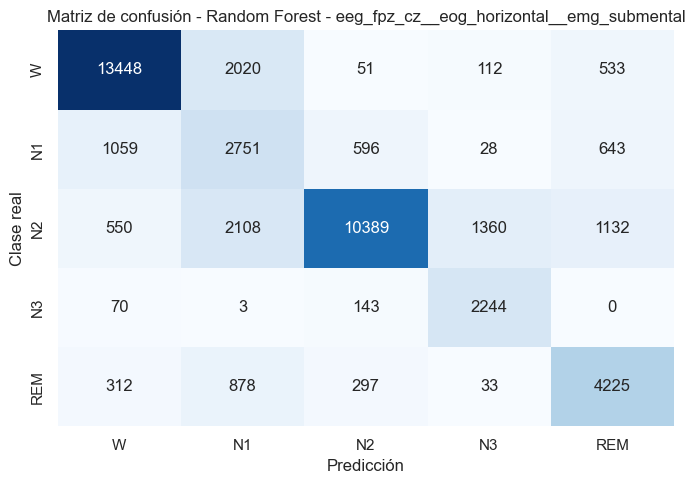

,W,N1,N2,N3,REM
W,13448,2020,51,112,533
N1,1059,2751,596,28,643
N2,550,2108,10389,1360,1132
N3,70,3,143,2244,0
REM,312,878,297,33,4225


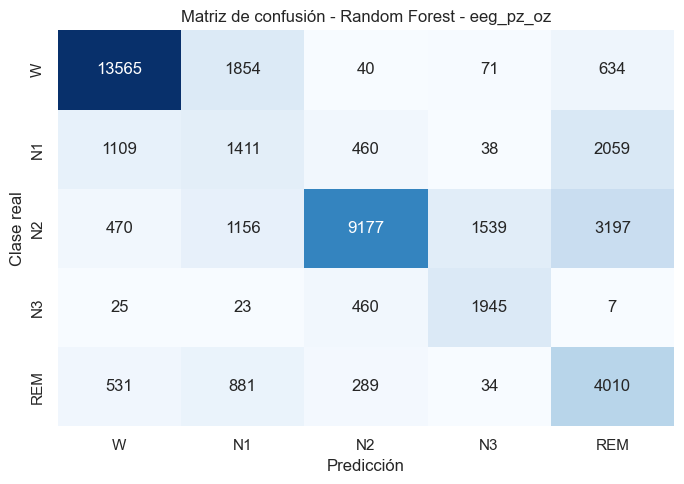

,W,N1,N2,N3,REM
W,13565,1854,40,71,634
N1,1109,1411,460,38,2059
N2,470,1156,9177,1539,3197
N3,25,23,460,1945,7
REM,531,881,289,34,4010


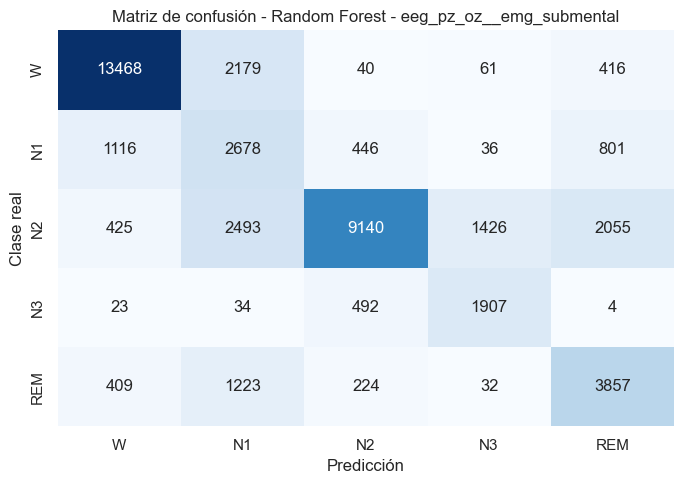

,W,N1,N2,N3,REM
W,13468,2179,40,61,416
N1,1116,2678,446,36,801
N2,425,2493,9140,1426,2055
N3,23,34,492,1907,4
REM,409,1223,224,32,3857


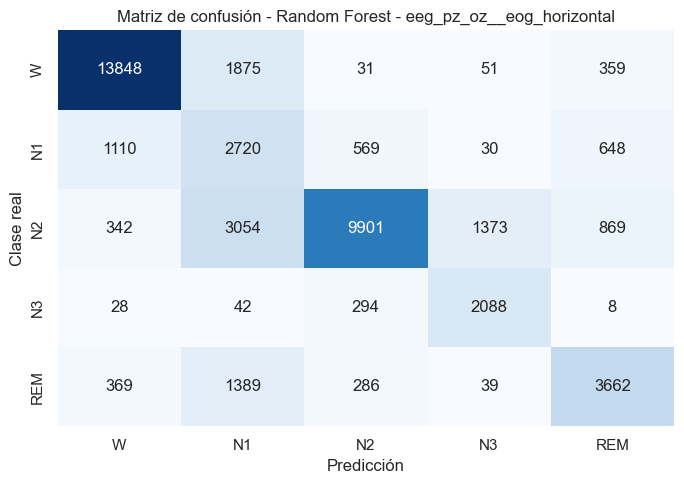

,W,N1,N2,N3,REM
W,13848,1875,31,51,359
N1,1110,2720,569,30,648
N2,342,3054,9901,1373,869
N3,28,42,294,2088,8
REM,369,1389,286,39,3662


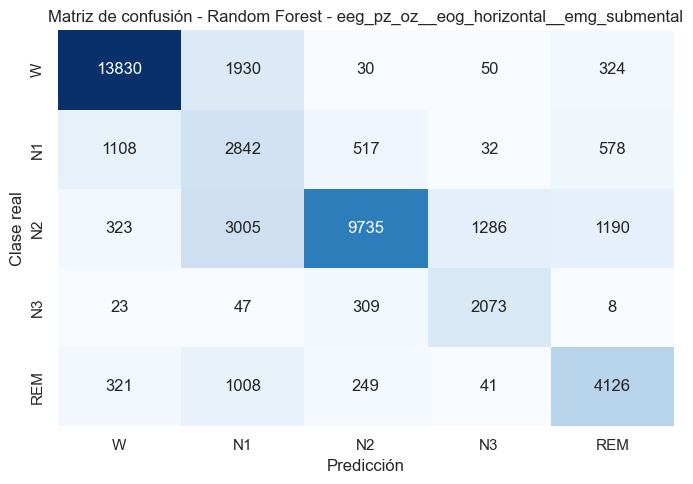

,W,N1,N2,N3,REM
W,13830,1930,30,50,324
N1,1108,2842,517,32,578
N2,323,3005,9735,1286,1190
N3,23,47,309,2073,8
REM,321,1008,249,41,4126


In [21]:
plot_confusion_matrices("Random Forest", rf_test_eval_df)

### Importancia de variables y guardado de artefactos

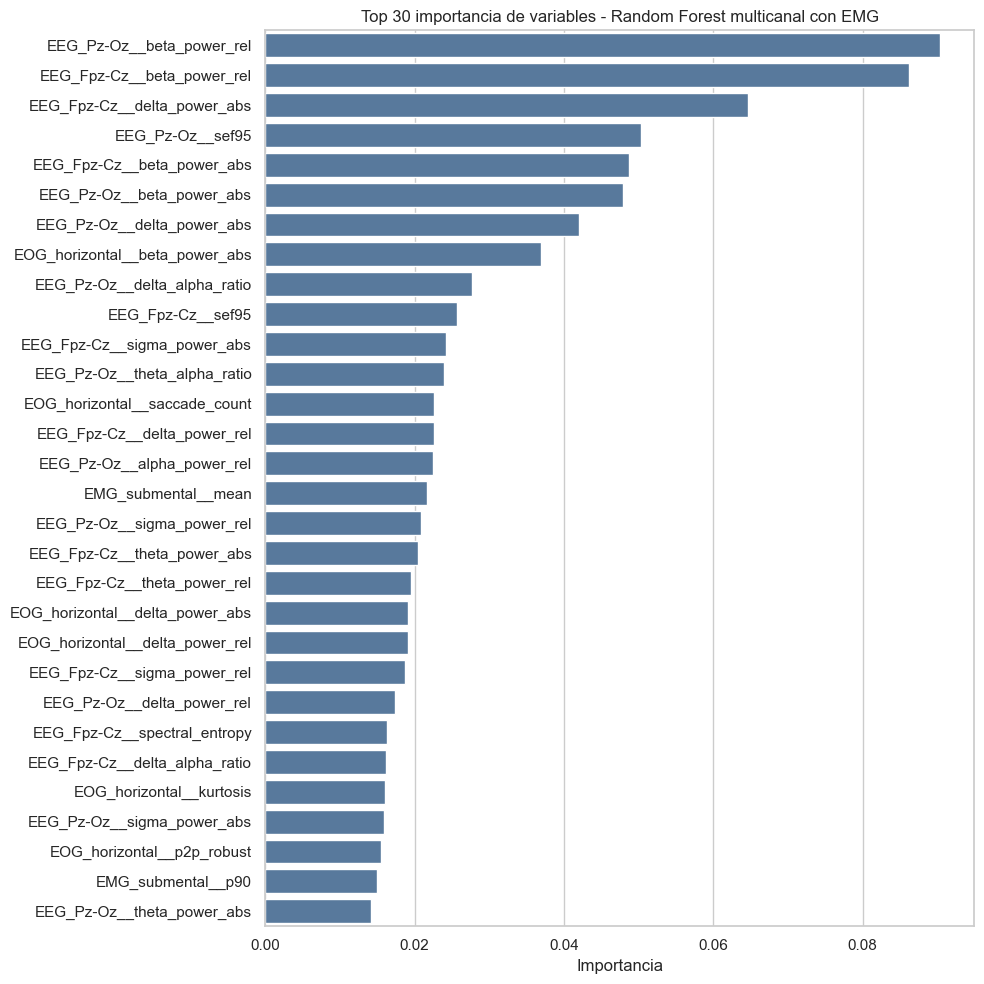

,feature,importance
17,EEG_Pz-Oz__beta_power_rel,0.090382
3,EEG_Fpz-Cz__beta_power_rel,0.086248
5,EEG_Fpz-Cz__delta_power_abs,0.064691
21,EEG_Pz-Oz__sef95,0.050348
2,EEG_Fpz-Cz__beta_power_abs,0.048742
16,EEG_Pz-Oz__beta_power_abs,0.047947
19,EEG_Pz-Oz__delta_power_abs,0.042067
33,EOG_horizontal__beta_power_abs,0.036881
18,EEG_Pz-Oz__delta_alpha_ratio,0.027651
7,EEG_Fpz-Cz__sef95,0.025602


In [22]:
rf_feature_importance = plot_feature_importance("Random Forest", rf_search.best_estimator_)

rf_paths = save_artifacts(
    "Random Forest",
    "random-forest",
    rf_search,
    rf_metrics,
    rf_metrics_by_combo,
    rf_per_class_by_combo,
    rf_feature_importance,
)

## Modelo 4: Árbol de Decisión

### Búsqueda de hiperparámetros

In [23]:
dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
)

dt_param_distributions = {
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 8, 10, 15, 20, None],
    "min_samples_split": [2, 10, 50, 100],
    "min_samples_leaf": [1, 5, 20, 50, 100],
    "max_features": [None, "sqrt", 0.5],
}

dt_search = run_search("Decision Tree", dt_model, dt_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  42.1s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  42.4s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  42.8s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  43.5s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  43.7s
[CV] END criterion=gini, max_depth=None, max_features=0.5, min_samples_leaf=1, min_samples_split=2; total time=  51.1s
[CV] END criterion=gini, max_depth=None, max_features=0.5, min_samples_leaf=1, min_samples_split=2; total time=  55.6s
[CV] END criterion=gini, max_depth=None, max_features=0.5, min_samples_leaf=1, min_samples_split=2; total 

{'min_samples_split': 50,
 'min_samples_leaf': 100,
 'max_features': None,
 'max_depth': 15,
 'criterion': 'gini'}

In [24]:
dt_cv_results = show_cv_results(dt_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
3,1,0.647971,0.014866,0.726317,0.004315,"{'min_samples_split': 50, 'min_samples_leaf': ..."
8,2,0.644543,0.014903,0.773592,0.003845,"{'min_samples_split': 2, 'min_samples_leaf': 5..."
1,3,0.639584,0.013337,0.793023,0.003771,"{'min_samples_split': 50, 'min_samples_leaf': ..."
6,4,0.599927,0.013055,0.624706,0.006512,"{'min_samples_split': 100, 'min_samples_leaf':..."
5,5,0.599673,0.013209,0.624825,0.006526,"{'min_samples_split': 10, 'min_samples_leaf': ..."
7,6,0.589019,0.012366,0.635689,0.009200,"{'min_samples_split': 10, 'min_samples_leaf': ..."
4,7,0.573218,0.021892,0.605742,0.007232,"{'min_samples_split': 10, 'min_samples_leaf': ..."
0,8,0.554158,0.016143,1.000000,0.000000,"{'min_samples_split': 2, 'min_samples_leaf': 1..."
2,9,0.478429,0.035930,0.509662,0.011159,"{'min_samples_split': 50, 'min_samples_leaf': ..."
9,10,0.464719,0.016016,0.484289,0.006866,"{'min_samples_split': 50, 'min_samples_leaf': ..."


### Evaluación global en test y por combinación de canales

=== Decision Tree - evaluación global en test ===


accuracy                                                      0.635843
macro_f1                                                      0.598628
balanced_accuracy                                             0.652325
cohens_kappa                                                  0.523576
best_cv_macro_f1                                              0.647971
best_params          {'min_samples_split': 50, 'min_samples_leaf': ...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.857008,0.765399,0.808618,193968
1,N1,0.263786,0.507698,0.347184,60924
2,N2,0.883633,0.505454,0.643064,186468
3,N3,0.534909,0.828184,0.649997,29520
4,REM,0.465635,0.654888,0.544280,68940


              precision    recall  f1-score   support

           W       0.86      0.77      0.81    193968
          N1       0.26      0.51      0.35     60924
          N2       0.88      0.51      0.64    186468
          N3       0.53      0.83      0.65     29520
         REM       0.47      0.65      0.54     68940

    accuracy                           0.64    539820
   macro avg       0.60      0.65      0.60    539820
weighted avg       0.73      0.64      0.66    539820



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,44985,0.582950,0.549966,0.613116,0.460946
2,eeg_fpz_cz__eeg_pz_oz,44985,0.633633,0.589466,0.636902,0.517538
3,eeg_fpz_cz__eeg_pz_oz__emg_submental,44985,0.654463,0.620666,0.672635,0.545772
4,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,44985,0.655330,0.623730,0.674919,0.548482
5,eeg_fpz_cz__eeg_pz_oz__eog_horizontal__emg_sub...,44985,0.671713,0.640819,0.696373,0.569103
6,eeg_fpz_cz__emg_submental,44985,0.600800,0.579927,0.649692,0.487083
7,eeg_fpz_cz__eog_horizontal,44985,0.625586,0.598895,0.658270,0.512649
8,eeg_fpz_cz__eog_horizontal__emg_submental,44985,0.646482,0.618113,0.681904,0.538681
9,eeg_pz_oz,44985,0.619406,0.545883,0.594140,0.497021
10,eeg_pz_oz__emg_submental,44985,0.643659,0.593688,0.636302,0.529052


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.250635,0.388418,0.304674,5077
2,eeg_fpz_cz,N2,0.905536,0.451573,0.602628,15539
3,eeg_fpz_cz,N3,0.515474,0.866667,0.646452,2460
4,eeg_fpz_cz,REM,0.327534,0.658660,0.437507,5745
0,eeg_fpz_cz,W,0.827473,0.700260,0.758570,16164
6,eeg_fpz_cz__eeg_pz_oz,N1,0.242838,0.430766,0.310587,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.892058,0.513225,0.651579,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.561033,0.865041,0.680633,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.417800,0.577720,0.484915,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.842700,0.797760,0.819615,16164


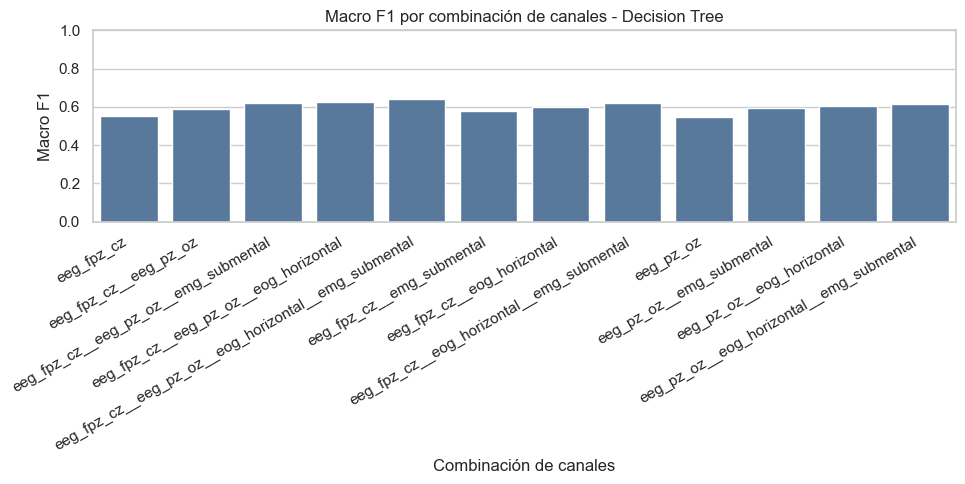

In [25]:
dt_y_pred, dt_metrics, dt_per_class = evaluate_global("Decision Tree", dt_search)
dt_test_eval_df, dt_metrics_by_combo, dt_per_class_by_combo = evaluate_by_combo("Decision Tree", dt_y_pred)

### Matriz de confusión global y por combinación

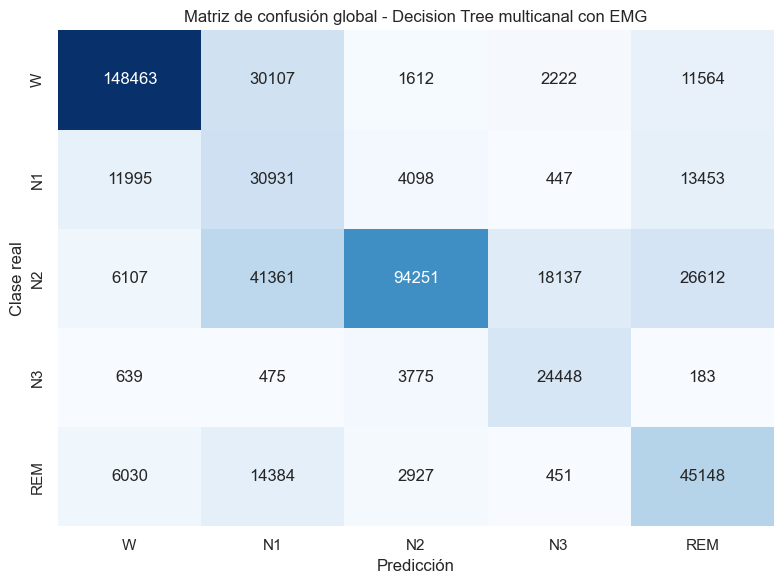

,W,N1,N2,N3,REM
W,148463,30107,1612,2222,11564
N1,11995,30931,4098,447,13453
N2,6107,41361,94251,18137,26612
N3,639,475,3775,24448,183
REM,6030,14384,2927,451,45148


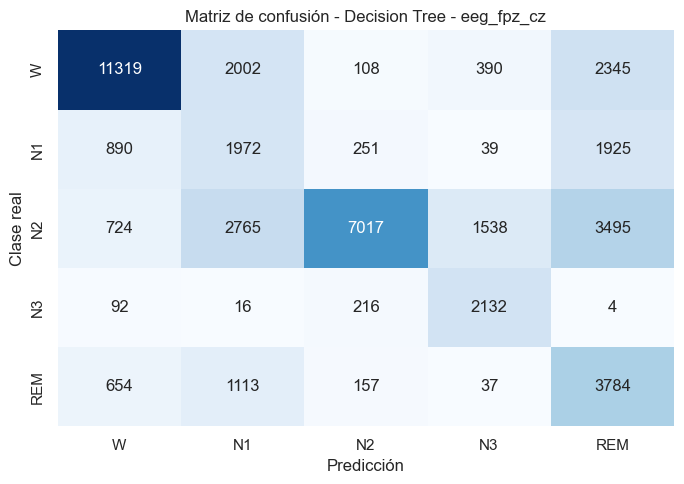

,W,N1,N2,N3,REM
W,11319,2002,108,390,2345
N1,890,1972,251,39,1925
N2,724,2765,7017,1538,3495
N3,92,16,216,2132,4
REM,654,1113,157,37,3784


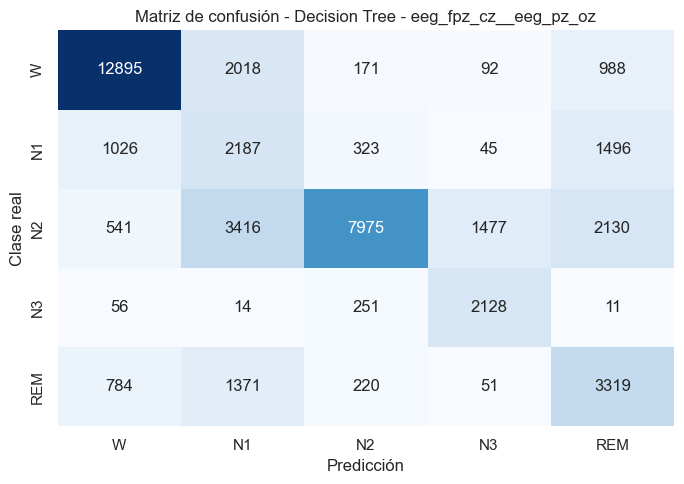

,W,N1,N2,N3,REM
W,12895,2018,171,92,988
N1,1026,2187,323,45,1496
N2,541,3416,7975,1477,2130
N3,56,14,251,2128,11
REM,784,1371,220,51,3319


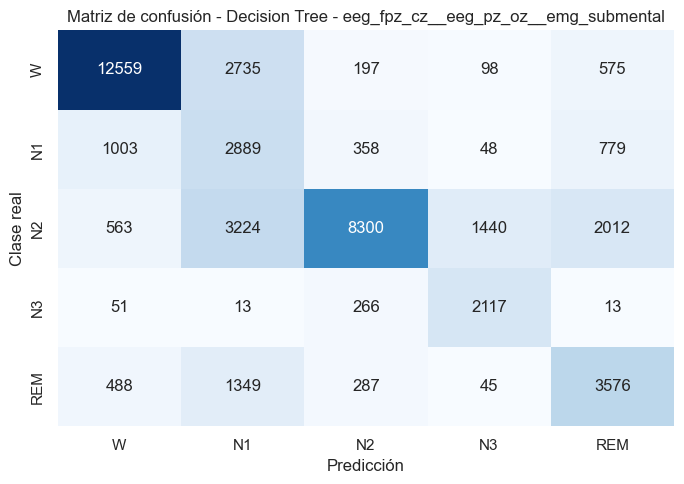

,W,N1,N2,N3,REM
W,12559,2735,197,98,575
N1,1003,2889,358,48,779
N2,563,3224,8300,1440,2012
N3,51,13,266,2117,13
REM,488,1349,287,45,3576


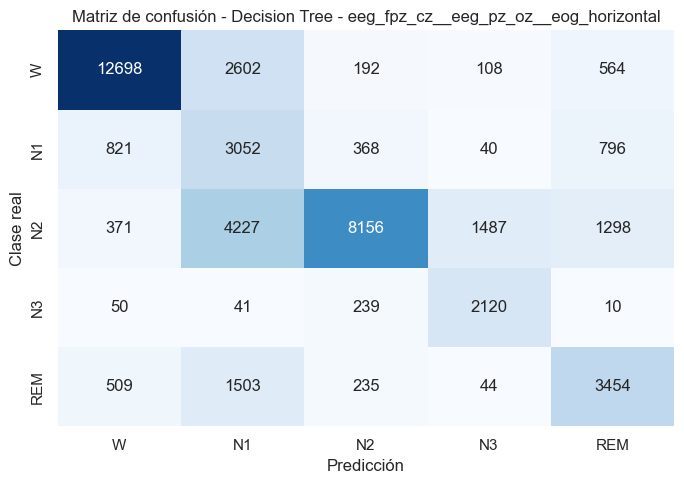

,W,N1,N2,N3,REM
W,12698,2602,192,108,564
N1,821,3052,368,40,796
N2,371,4227,8156,1487,1298
N3,50,41,239,2120,10
REM,509,1503,235,44,3454


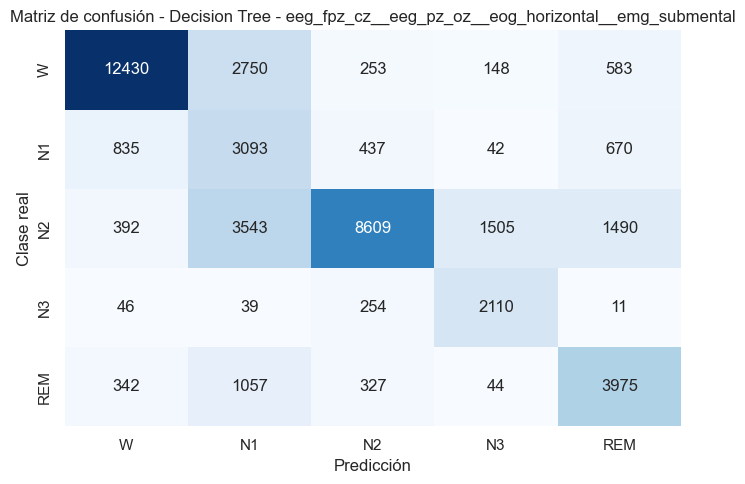

,W,N1,N2,N3,REM
W,12430,2750,253,148,583
N1,835,3093,437,42,670
N2,392,3543,8609,1505,1490
N3,46,39,254,2110,11
REM,342,1057,327,44,3975


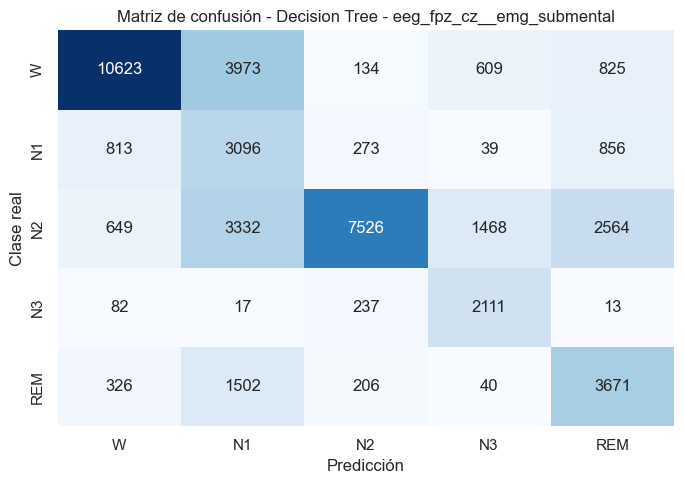

,W,N1,N2,N3,REM
W,10623,3973,134,609,825
N1,813,3096,273,39,856
N2,649,3332,7526,1468,2564
N3,82,17,237,2111,13
REM,326,1502,206,40,3671


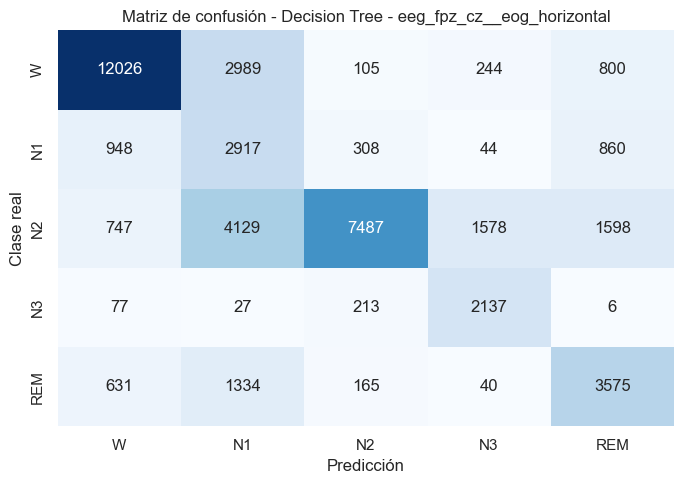

,W,N1,N2,N3,REM
W,12026,2989,105,244,800
N1,948,2917,308,44,860
N2,747,4129,7487,1578,1598
N3,77,27,213,2137,6
REM,631,1334,165,40,3575


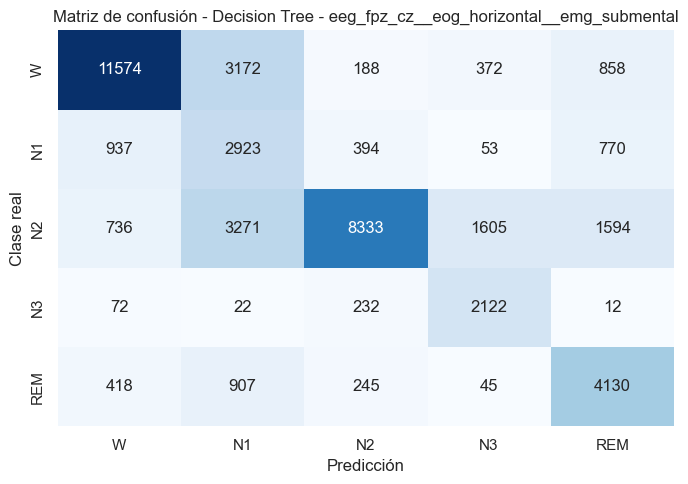

,W,N1,N2,N3,REM
W,11574,3172,188,372,858
N1,937,2923,394,53,770
N2,736,3271,8333,1605,1594
N3,72,22,232,2122,12
REM,418,907,245,45,4130


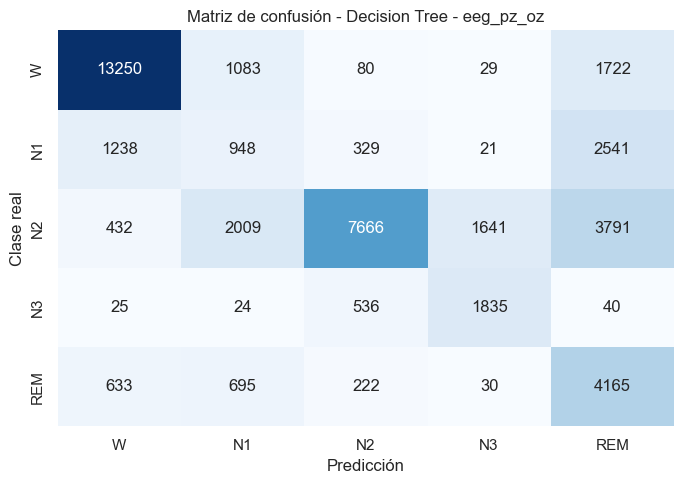

,W,N1,N2,N3,REM
W,13250,1083,80,29,1722
N1,1238,948,329,21,2541
N2,432,2009,7666,1641,3791
N3,25,24,536,1835,40
REM,633,695,222,30,4165


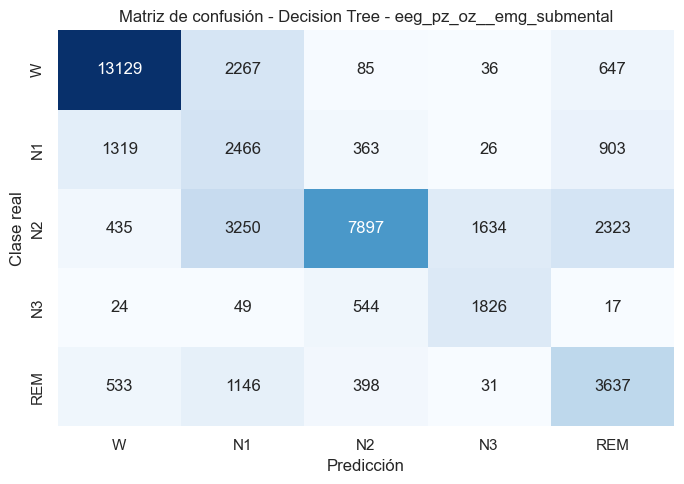

,W,N1,N2,N3,REM
W,13129,2267,85,36,647
N1,1319,2466,363,26,903
N2,435,3250,7897,1634,2323
N3,24,49,544,1826,17
REM,533,1146,398,31,3637


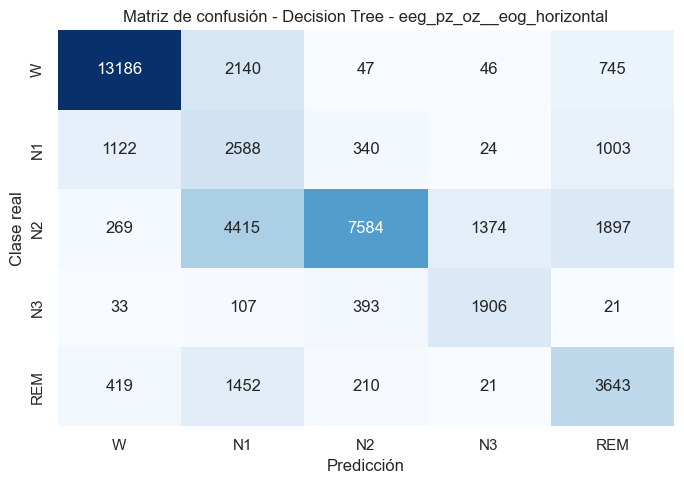

,W,N1,N2,N3,REM
W,13186,2140,47,46,745
N1,1122,2588,340,24,1003
N2,269,4415,7584,1374,1897
N3,33,107,393,1906,21
REM,419,1452,210,21,3643


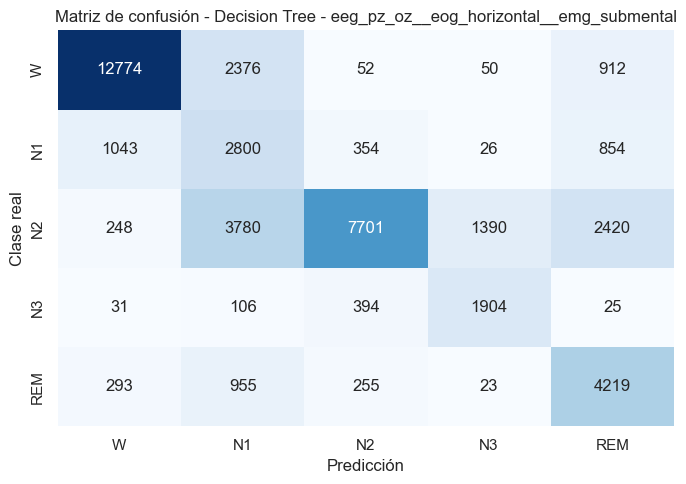

,W,N1,N2,N3,REM
W,12774,2376,52,50,912
N1,1043,2800,354,26,854
N2,248,3780,7701,1390,2420
N3,31,106,394,1904,25
REM,293,955,255,23,4219


In [26]:
plot_confusion_matrices("Decision Tree", dt_test_eval_df)

### Importancia de variables y guardado de artefactos

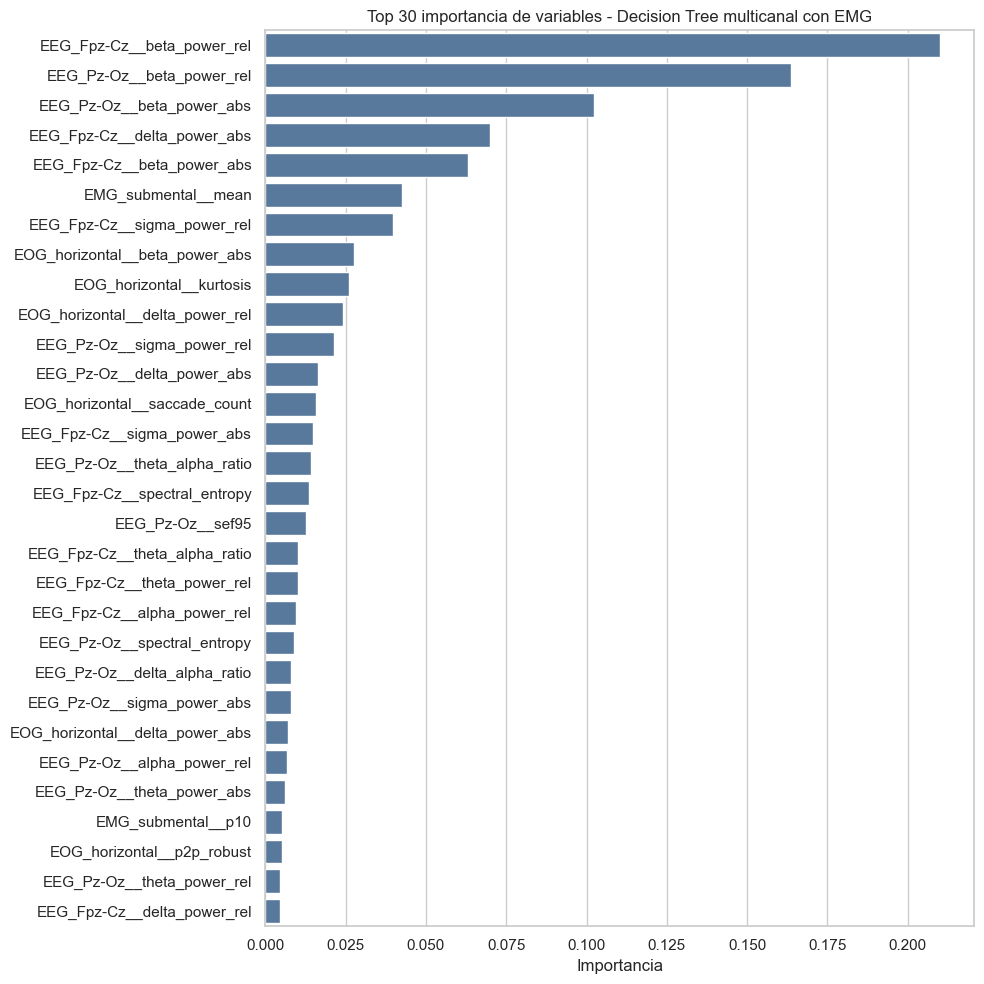

,feature,importance
3,EEG_Fpz-Cz__beta_power_rel,0.210117
17,EEG_Pz-Oz__beta_power_rel,0.163509
16,EEG_Pz-Oz__beta_power_abs,0.102418
5,EEG_Fpz-Cz__delta_power_abs,0.069971
2,EEG_Fpz-Cz__beta_power_abs,0.063178
28,EMG_submental__mean,0.042700
9,EEG_Fpz-Cz__sigma_power_rel,0.039628
33,EOG_horizontal__beta_power_abs,0.027609
37,EOG_horizontal__kurtosis,0.026064
35,EOG_horizontal__delta_power_rel,0.024278


In [27]:
dt_feature_importance = plot_feature_importance("Decision Tree", dt_search.best_estimator_)

dt_paths = save_artifacts(
    "Decision Tree",
    "decision-tree",
    dt_search,
    dt_metrics,
    dt_metrics_by_combo,
    dt_per_class_by_combo,
    dt_feature_importance,
)

## Comparación de modelos

Resumen de las métricas en test y del mejor `f1_macro` de validación cruzada para los cuatro modelos. El ranking se ordena por `macro_f1` en test.

,model,best_cv_macro_f1,accuracy,macro_f1,balanced_accuracy,cohens_kappa,best_params
0,XGBoost,0.705738,0.727394,0.675106,0.721068,0.634825,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estim..."
1,LightGBM,0.704330,0.720372,0.669113,0.716874,0.626231,"{'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav..."
2,Random Forest,0.695783,0.714186,0.663476,0.707823,0.617456,"{'n_estimators': 100, 'min_samples_split': 100..."
3,Decision Tree,0.647971,0.635843,0.598628,0.652325,0.523576,"{'min_samples_split': 50, 'min_samples_leaf': ..."


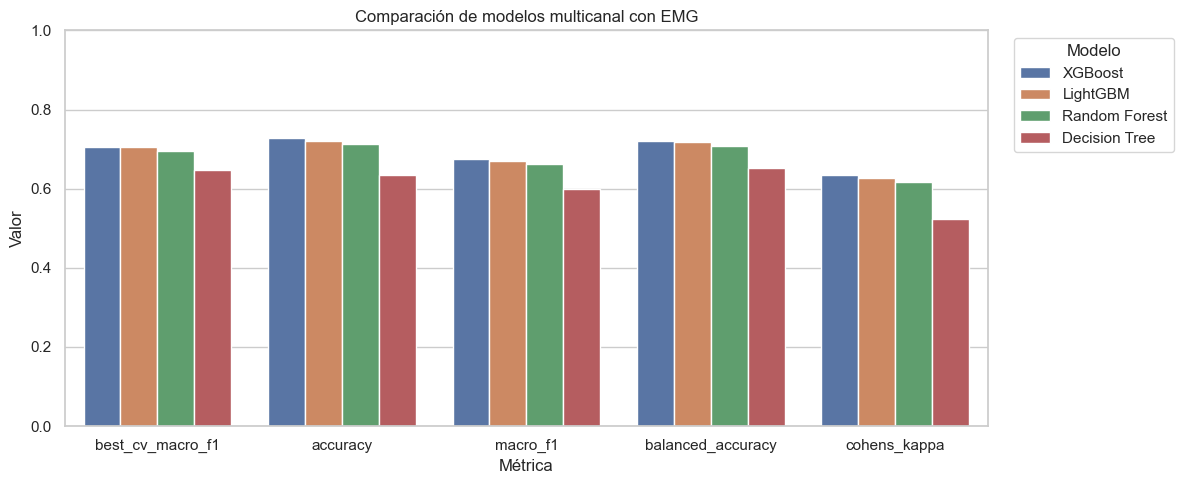

Mejor modelo por macro F1 en test: XGBoost (0.6751)


In [28]:
comparison = pd.DataFrame(
    [
        {
            "model": model_name,
            "best_cv_macro_f1": result["metrics"]["best_cv_macro_f1"],
            "accuracy": result["metrics"]["accuracy"],
            "macro_f1": result["metrics"]["macro_f1"],
            "balanced_accuracy": result["metrics"]["balanced_accuracy"],
            "cohens_kappa": result["metrics"]["cohens_kappa"],
            "best_params": result["metrics"]["best_params"],
        }
        for model_name, result in results.items()
    ]
).sort_values("macro_f1", ascending=False).reset_index(drop=True)

comparison.to_csv(COMPARISON_PATH, index=False)
display(comparison)

comparison_long = comparison.melt(
    id_vars="model",
    value_vars=["best_cv_macro_f1", "accuracy", "macro_f1", "balanced_accuracy", "cohens_kappa"],
    var_name="metric",
    value_name="value",
)

plt.figure(figsize=(12, 5))
sns.barplot(data=comparison_long, x="metric", y="value", hue="model")
plt.title("Comparación de modelos multicanal con EMG")
plt.xlabel("Métrica")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

best_model_name = comparison.loc[0, "model"]
print(f"Mejor modelo por macro F1 en test: {best_model_name} ({comparison.loc[0, 'macro_f1']:.4f})")

model,Decision Tree,LightGBM,Random Forest,XGBoost
channel_combo,,,,
eeg_fpz_cz,0.549966,0.611972,0.603918,0.615726
eeg_fpz_cz__eeg_pz_oz,0.589466,0.666678,0.668693,0.674549
eeg_fpz_cz__eeg_pz_oz__emg_submental,0.620666,0.700522,0.690448,0.706334
eeg_fpz_cz__eeg_pz_oz__eog_horizontal,0.623730,0.705587,0.703492,0.712997
eeg_fpz_cz__eeg_pz_oz__eog_horizontal__emg_submental,0.640819,0.726693,0.714904,0.733686
eeg_fpz_cz__emg_submental,0.579927,0.652772,0.632938,0.657899
eeg_fpz_cz__eog_horizontal,0.598895,0.681013,0.678711,0.687965
eeg_fpz_cz__eog_horizontal__emg_submental,0.618113,0.704488,0.691318,0.711946
eeg_pz_oz,0.545883,0.587752,0.596212,0.594437


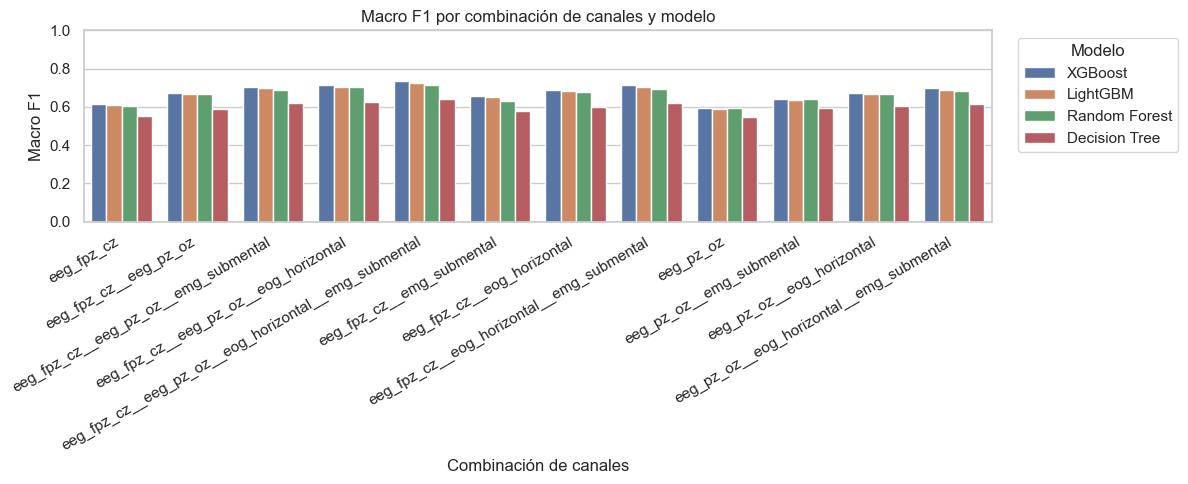

In [29]:
comparison_by_combo = pd.concat(
    [
        result["metrics_by_combo"].assign(model=model_name)
        for model_name, result in results.items()
    ],
    ignore_index=True,
)
comparison_by_combo.to_csv(COMPARISON_BY_COMBO_PATH, index=False)

display(
    comparison_by_combo.pivot(index="channel_combo", columns="model", values="macro_f1")
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=comparison_by_combo[comparison_by_combo["channel_combo"] != "overall"],
    x="channel_combo",
    y="macro_f1",
    hue="model",
)
plt.title("Macro F1 por combinación de canales y modelo")
plt.xlabel("Combinación de canales")
plt.ylabel("Macro F1")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Registro en MLflow

Cada modelo se registra como un *run* en el experimento `sleep-staging-baseline-multicanal`, el mismo que usa `08_train_base_models_multichannel.ipynb`. Los runs y los modelos registrados llevan el sufijo `emg` para distinguirlos de los del notebook 08. Los datos se leen de los artefactos guardados arriba (`.joblib` y `model_info_<modelo>_multicanal_emg.json`), así que no hace falta reentrenar. Basta con ejecutar antes las celdas de configuración, carga y preparación de matrices.

Por cada modelo se registran:

- **Parámetros:** mejores hiperparámetros y configuración de la búsqueda.
- **Métricas:** globales en test, `best_cv_macro_f1` y métricas por combinación de canales (p. ej. `macro_f1__eeg_pz_oz`).
- **Artefactos:** matriz de confusión, CSV/JSON de métricas e importancia de variables y el bundle `.joblib` de inferencia.
- **Modelo:** en formato `mlflow.sklearn` (serializado con `cloudpickle`) y registrado en el Model Registry como `sleep-staging-<modelo>-multicanal-emg`.

Se usa `mlflow.sklearn.log_model` también para XGBoost porque `mlflow.xgboost.log_model` llama a `XGBClassifier.save_model()`, que falla con scikit-learn >= 1.8 (`_estimator_type` undefined).

**Requisitos:** `MLFLOW_TRACKING_URI` definido en `.env` (ver `.env.example`) y credenciales de AWS configuradas, porque el servidor guarda los artefactos en S3. Sin credenciales, parámetros y métricas se registran, pero la subida de artefactos falla.

In [32]:
load_dotenv(PROJECT_ROOT / ".env")

MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI")
MLFLOW_EXPERIMENT_NAME = "sleep-staging-baseline-multicanal"
REGISTER_MODELS = True

os.environ.setdefault("MLFLOW_ENABLE_PROXY_MULTIPART_UPLOAD", "true")
os.environ.setdefault("MLFLOW_MULTIPART_UPLOAD_MINIMUM_FILE_SIZE", str(50 * 1024**2))
os.environ.setdefault("MLFLOW_HTTP_REQUEST_TIMEOUT", "600")
os.environ.setdefault("MLFLOW_ARTIFACT_UPLOAD_DOWNLOAD_TIMEOUT", "1800")

MAX_EXTRA_ARTIFACT_MB = 100

MODELS_TO_LOG = {
    "XGBoost": "xgboost",
    "LightGBM": "lightgbm",
    "Random Forest": "random-forest",
    "Decision Tree": "decision-tree",
}

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
experiment = mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

print(f"Tracking URI: {MLFLOW_TRACKING_URI}")
print(f"Experiment: {experiment.name}")

MlflowException: API request to https://18.119.196.100/api/2.0/mlflow/experiments/get-by-name failed with exception HTTPSConnectionPool(host='18.119.196.100', port=443): Max retries exceeded with url: /api/2.0/mlflow/experiments/get-by-name?experiment_name=sleep-staging-baseline-multicanal (Caused by SSLError(SSLCertVerificationError(1, '[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: certificate has expired (_ssl.c:1032)')))

In [ ]:
mlflow_label_ids = label_encoder.transform(class_labels)
combo_metric_names = ["accuracy", "macro_f1", "balanced_accuracy", "cohens_kappa"]
mlflow_runs = {}
mlflow_failed = {}

for model_name, model_slug in MODELS_TO_LOG.items():
    paths = get_artifact_paths(model_slug)
    if not paths["joblib"].exists():
        print(f"[{model_name}] No se encontró {paths['joblib']}; se omite.")
        continue

    bundle = joblib.load(paths["joblib"])
    with open(paths["info"]) as f:
        info = json.load(f)

    model = bundle["model"]
    y_pred_mlflow = model.predict(X_test[bundle["feature_columns"]])

    try:
        with mlflow.start_run(experiment_id=experiment.experiment_id, run_name=f"{model_slug}_multicanal_emg") as run:
            mlflow.set_tags(
                {
                    "model_type": "baseline",
                    "model_family": model_name,
                    "signals_used": "EEG Fpz-Cz y/o EEG Pz-Oz + EOG horizontal y/o EMG submental (opcionales)",
                    "stage": "hyperparameter_search",
                    "notebook": "10_train_base_models_multichannel",
                }
            )

            mlflow.log_params(info["best_params"])
            mlflow.log_params(
                {
                    "cv_splits": CV_SPLITS,
                    "n_iter_search": N_ITER_SEARCH,
                    "scoring": SCORING,
                    "num_class": len(class_labels),
                    "n_features": len(bundle["feature_columns"]),
                    "excluded_id_columns": ",".join(ID_COLUMNS),
                    "excluded_control_columns": ",".join(CONTROL_COLUMNS),
                    "categorical_columns": ",".join(CATEGORICAL_COLUMNS),
                }
            )

            mlflow.log_metrics(
                {
                    "accuracy": info["accuracy"],
                    "macro_f1": info["macro_f1"],
                    "balanced_accuracy": info["balanced_accuracy"],
                    "cohens_kappa": info["cohens_kappa"],
                    "best_cv_macro_f1": info["best_cv_macro_f1"],
                }
            )

            for row in info["metrics_by_channel_combo"]:
                if row["channel_combo"] == "overall":
                    continue
                mlflow.log_metrics(
                    {f"{metric}__{row['channel_combo']}": row[metric] for metric in combo_metric_names}
                )

            conf_matrix_df = pd.DataFrame(
                confusion_matrix(y_test, y_pred_mlflow, labels=mlflow_label_ids),
                index=class_labels,
                columns=class_labels,
            )
            fig, ax = plt.subplots(figsize=(8, 6))
            sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
            ax.set_title(f"Matriz de confusión - {model_name} multicanal con EMG")
            ax.set_xlabel("Predicción")
            ax.set_ylabel("Clase real")
            fig.tight_layout()
            mlflow.log_figure(fig, "confusion_matrix_test.png")
            plt.close(fig)

            for artifact_key in ["info", "metrics_by_combo", "per_class_by_combo", "feature_importance", "joblib"]:
                artifact_mb = paths[artifact_key].stat().st_size / 1024**2
                if artifact_key == "joblib" and artifact_mb > MAX_EXTRA_ARTIFACT_MB:
                    print(f"[{model_name}] Se omite {paths[artifact_key].name} ({artifact_mb:.0f} MB) como artefacto extra.")
                    continue
                mlflow.log_artifact(str(paths[artifact_key]), artifact_path="files")

            mlflow.sklearn.log_model(
                sk_model=model,
                name="model",
                serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
                input_example=X_test[bundle["feature_columns"]].head(5),
                registered_model_name=f"sleep-staging-{model_slug}-multicanal-emg" if REGISTER_MODELS else None,
            )

            mlflow_runs[model_name] = run.info.run_id
            print(f"[{model_name}] registrado en MLflow. run_id: {run.info.run_id}")
    except Exception as exc:
        mlflow_failed[model_name] = f"{type(exc).__name__}: {exc}"
        print(f"[{model_name}] falló el registro: {mlflow_failed[model_name][:500]}")

display(pd.Series(mlflow_runs, name="run_id"))
if mlflow_failed:
    display(pd.Series(mlflow_failed, name="error"))

'mlflow_label_ids = label_encoder.transform(class_labels)\ncombo_metric_names = ["accuracy", "macro_f1", "balanced_accuracy", "cohens_kappa"]\nmlflow_runs = {}\nmlflow_failed = {}\n\nfor model_name, model_slug in MODELS_TO_LOG.items():\n    paths = get_artifact_paths(model_slug)\n    if not paths["joblib"].exists():\n        print(f"[{model_name}] No se encontró {paths[\'joblib\']}; se omite.")\n        continue\n\n    bundle = joblib.load(paths["joblib"])\n    with open(paths["info"]) as f:\n        info = json.load(f)\n\n    model = bundle["model"]\n    y_pred_mlflow = model.predict(X_test[bundle["feature_columns"]])\n\n    try:\n        with mlflow.start_run(experiment_id=experiment.experiment_id, run_name=f"{model_slug}_multicanal_emg") as run:\n            mlflow.set_tags(\n                {\n                    "model_type": "baseline",\n                    "model_family": model_name,\n                    "signals_used": "EEG Fpz-Cz y/o EEG Pz-Oz + EOG horizontal y/o EMG submenta